# Score estimation and Richardson extrapolation


This notebook reproduces the three-estimator score comparison, posterior diagnostics, posterior-sample budget, and clean-score fields. It evaluates the released models and writes tables and figures under `res/8gauss/score/`.


## Setup

In [ ]:
import json
import os
import subprocess
import sys
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import omegaconf
import pandas as pd
import torch

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "requirements.txt").is_file()
    and (p / "src/engression/engression").is_dir()
    and (p / "exp/reproduce_score_estimation.ipynb").is_file()
)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.path.insert(1, str(ROOT / "src/engression"))

from utils.eight_gauss import (
    compute_noisy_score_mse_grid,
    compute_noisy_score_mse_grid_generalized,
    eight_gaussians,
    eight_gaussians_centers,
    eight_gaussians_score,
    empirical_mode_weights_nearest_center,
    energy_distance_unbiased,
)
from utils.experiment_io import (
    save_torch_atomic,
    set_reproducible_seed,
    write_csv_atomic,
    write_json_atomic,
)
from utils.noise_geometry import (
    generalized_gaussian_actual_rms,
    reference_rho_to_sigma,
    sample_generalized_gaussian_noise,
    spd_2d_from_uv,
)
from utils.sampling import (
    EngressorSampler,
    generalized_gaussian_log_weights,
    generalized_importance_noisy_score,
    load_parameter_conditioned_engressor,
    mc_score_from_posterior_samples_spd,
    richardson_extrapolate,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_reproducible_seed(42)
MODEL_ROOT = ROOT / "models"


## Five-parameter score comparison


- **Score accuracy:** NMSE measures squared error relative to the reference-score energy; cosine measures directional agreement; the norm ratio compares score magnitudes.
- **Posterior accuracy:** Mean error, covariance trace, mixture-mode mass, and energy distance compare posterior samples with the importance-sampled posterior.
- **Reference precision:** Independent half-bank scores and posterior resamples measure numerical uncertainty in the reference.


In [ ]:
FIVE_PARAM_DEVICE = device
FIVE_PARAM_MODEL_ROOT = MODEL_ROOT / "score_and_diffusion"
FIVE_PARAM_SCORE_DIR = Path("res/8gauss/score/full5")
FIVE_PARAM_SCORE_DIR.mkdir(parents=True, exist_ok=True)
FIVE_PARAM_DATA_RADIUS = 2.0
FIVE_PARAM_STD_CLEAN = 0.2
FIVE_PARAM_MODEL_SPECS = [
    {
        "training_seed": 42,
        "run_name": "full_spd_seed42",
        "checkpoint": "model.pt",
    },
    {
        "training_seed": 43,
        "run_name": "full_spd_seed43",
        "checkpoint": "model.pt",
    },
]

FIVE_PARAM_PLOT_RC = {
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "lines.linewidth": 1.2,
    "lines.markersize": 3.5,
    "axes.linewidth": 0.8,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
}
FIVE_PARAM_OUT_DIR = FIVE_PARAM_SCORE_DIR

COMPARISON_DIR = ROOT / "res/8gauss/score/comparison_full5_80k"
COMPARISON_REFERENCE_DIR = COMPARISON_DIR / "reference"
COMPARISON_TABLE_DIR = COMPARISON_DIR / "tables"
COMPARISON_FIGURE_DIR = COMPARISON_DIR / "figures"
COMPARISON_METHODS = ["et_posterior", "et_dsm", "hyvarinen"]
COMPARISON_METHOD_LABELS = {
    "et_posterior": "ET posterior",
    "et_dsm": "ET-DSM",
    "hyvarinen": "Hyvärinen",
}
COMPARISON_FACTORS = ["beta", "lambda", "rho", "u", "v"]
COMPARISON_FACTOR_LABELS = {
    "beta": r"$\beta$ (1.3–2)",
    "lambda": r"$\lambda$ (1–2.5)",
    "rho": r"$\sigma$ (0.1–0.75)",
    "u": r"$u$ ($-0.6$–$0.6$)",
    "v": r"$v$ ($-0.6$–$0.6$)",
}
COMPARISON_SCORE_METRICS = ["score_nmse", "score_cosine", "score_norm_ratio"]
COMPARISON_POSTERIOR_METRICS = [
    "posterior_mean_mse",
    "posterior_trace_ratio",
    "posterior_mode_tv",
    "posterior_energy",
    "posterior_energy_sd",
    "posterior_energy_excess",
]


In [ ]:
FIVE_PARAM_BASE_CONDITION = {
    "beta": 1.4,
    "lam": 1.8,
    "rho": 0.570322,
    "u": 0.0,
    "v": 0.6,
}
FIVE_PARAM_SWEEP_VALUES = {
    "beta": [1.3, 1.5, 1.75, 2.0],
    "lambda": [1.0, 1.4, 1.8, 2.5],
    "rho": [0.126738, 0.316846, 0.570322, 0.950537],
    "u": [-0.6, -0.3, 0.0, 0.3, 0.6],
    "v": [-0.6, -0.3, 0.0, 0.3, 0.6],
}
five_param_sweep_conditions = {}

for parameter_name, values in FIVE_PARAM_SWEEP_VALUES.items():
    conditions = []
    for value in values:
        condition = dict(FIVE_PARAM_BASE_CONDITION)
        if parameter_name == "lambda":
            condition["lam"] = float(value)
        elif parameter_name == "u":
            condition["u"] = float(value)
            condition["v"] = 0.0
        elif parameter_name == "v":
            condition["u"] = 0.0
            condition["v"] = float(value)
        else:
            condition[parameter_name] = float(value)
        condition["factor"] = parameter_name
        condition["factor_value"] = float(value)
        conditions.append(condition)
    five_param_sweep_conditions[parameter_name] = conditions


**Posterior score and distribution accuracy**


In [ ]:
FIVE_PARAM_BATTERY_SEED = 161803
FIVE_PARAM_BATTERY_N_PRIOR = 160_000
FIVE_PARAM_BATTERY_N_Y = 192
FIVE_PARAM_BATTERY_N_POSTERIOR = 192
FIVE_PARAM_BATTERY_N_ENERGY_Y = 48
FIVE_PARAM_BATTERY_IMPORTANCE_CHUNK = 32_768


def five_param_average_conditional_energy(samples_a, samples_b, max_queries):
    n_queries = min(int(max_queries), samples_a.shape[0], samples_b.shape[0])
    values = torch.stack(
        [
            energy_distance_unbiased(samples_a[index], samples_b[index])
            for index in range(n_queries)
        ]
    )
    return float(values.mean()), float(values.std(unbiased=True))


five_param_battery_conditions = []
for factor, conditions in five_param_sweep_conditions.items():
    for condition_index, condition in enumerate(conditions):
        five_param_battery_conditions.append(
            {
                **condition,
                "condition_id": f"{factor}_{condition_index:02d}",
            }
        )

five_param_quantitative_config = {
    "models": FIVE_PARAM_MODEL_SPECS,
    "seed": FIVE_PARAM_BATTERY_SEED,
    "n_prior": FIVE_PARAM_BATTERY_N_PRIOR,
    "n_y_per_condition": FIVE_PARAM_BATTERY_N_Y,
    "n_posterior_samples": FIVE_PARAM_BATTERY_N_POSTERIOR,
    "n_energy_queries": FIVE_PARAM_BATTERY_N_ENERGY_Y,
    "importance_chunk": FIVE_PARAM_BATTERY_IMPORTANCE_CHUNK,
    "conditions": five_param_battery_conditions,
}
write_json_atomic(
    five_param_quantitative_config,
    FIVE_PARAM_OUT_DIR / "quantitative_config.json",
)

set_reproducible_seed(FIVE_PARAM_BATTERY_SEED)
five_param_prior_bank = eight_gaussians(
    FIVE_PARAM_BATTERY_N_PRIOR,
    radius=FIVE_PARAM_DATA_RADIUS,
    std=FIVE_PARAM_STD_CLEAN,
    device=FIVE_PARAM_DEVICE,
)
FIVE_PARAM_INPUT_DIR = FIVE_PARAM_OUT_DIR / "evaluation_inputs"
FIVE_PARAM_INPUT_DIR.mkdir(parents=True, exist_ok=True)
save_torch_atomic(five_param_prior_bank.cpu(), FIVE_PARAM_INPUT_DIR / "prior_bank.pt")
five_param_prior_half_1, five_param_prior_half_2 = torch.chunk(
    five_param_prior_bank,
    2,
    dim=0,
)
five_param_battery_models = [
    {
        **load_parameter_conditioned_engressor(
            FIVE_PARAM_MODEL_ROOT / spec["run_name"],
            checkpoint=spec["checkpoint"],
            device=FIVE_PARAM_DEVICE,
        ),
        "spec": spec,
    }
    for spec in FIVE_PARAM_MODEL_SPECS
]
len(five_param_battery_conditions), len(five_param_battery_models)


In [ ]:
five_param_score_rows = []
five_param_reference_rows = []

for condition_index, condition in enumerate(five_param_battery_conditions):
    beta = float(condition["beta"])
    lam = float(condition["lam"])
    rho = float(condition["rho"])
    uv = torch.tensor(
        [condition["u"], condition["v"]],
        device=FIVE_PARAM_DEVICE,
        dtype=five_param_prior_bank.dtype,
    )
    Sigma = spd_2d_from_uv(uv)
    sigma = float(reference_rho_to_sigma(rho, beta, 2))
    actual_rms = float(generalized_gaussian_actual_rms(rho, beta, lam))
    condition_seed = FIVE_PARAM_BATTERY_SEED + 1_000 * (condition_index + 1)

    set_reproducible_seed(condition_seed)
    x_clean = eight_gaussians(
        FIVE_PARAM_BATTERY_N_Y,
        radius=FIVE_PARAM_DATA_RADIUS,
        std=FIVE_PARAM_STD_CLEAN,
        device=FIVE_PARAM_DEVICE,
    )
    noise = sample_generalized_gaussian_noise(
        FIVE_PARAM_BATTERY_N_Y,
        beta=beta,
        lam=lam,
        Sigma=Sigma,
        sigma=sigma,
        device=FIVE_PARAM_DEVICE,
        dtype=x_clean.dtype,
    )
    y = x_clean + noise

    oracle_score_1 = generalized_importance_noisy_score(
        y,
        five_param_prior_half_1,
        beta=beta,
        lam=lam,
        Sigma=Sigma,
        sigma=sigma,
        chunk_size=FIVE_PARAM_BATTERY_IMPORTANCE_CHUNK,
    )
    oracle_score_2 = generalized_importance_noisy_score(
        y,
        five_param_prior_half_2,
        beta=beta,
        lam=lam,
        Sigma=Sigma,
        sigma=sigma,
        chunk_size=FIVE_PARAM_BATTERY_IMPORTANCE_CHUNK,
    )
    oracle_score = 0.5 * (oracle_score_1 + oracle_score_2)
    oracle_score_power = oracle_score.square().sum(dim=1).mean().clamp_min(1e-12)
    oracle_split_nmse = float(
        (
            (oracle_score_1 - oracle_score_2).square().sum(dim=1).mean()
            / oracle_score_power
        )
    )

    save_torch_atomic(
        {
            "condition": condition,
            "sigma": sigma,
            "actual_rms": actual_rms,
            "y": y.cpu(),
            "reference": oracle_score.cpu(),
            "reference_half_1": oracle_score_1.cpu(),
            "reference_half_2": oracle_score_2.cpu(),
        },
        FIVE_PARAM_INPUT_DIR / f"{condition['condition_id']}.pt",
    )

    log_weights = generalized_gaussian_log_weights(
        y,
        five_param_prior_bank,
        beta=beta,
        lam=lam,
        Sigma=Sigma,
        sigma=sigma,
        chunk_size=FIVE_PARAM_BATTERY_IMPORTANCE_CHUNK,
    )
    probabilities = torch.softmax(log_weights, dim=1)
    oracle_posterior_mean = probabilities @ five_param_prior_bank
    importance_ess = probabilities.square().sum(dim=1).reciprocal()

    set_reproducible_seed(condition_seed + 101)
    oracle_indices_1 = torch.multinomial(
        probabilities,
        FIVE_PARAM_BATTERY_N_POSTERIOR,
        replacement=True,
    )
    set_reproducible_seed(condition_seed + 202)
    oracle_indices_2 = torch.multinomial(
        probabilities,
        FIVE_PARAM_BATTERY_N_POSTERIOR,
        replacement=True,
    )
    oracle_posterior_1 = five_param_prior_bank[oracle_indices_1]
    oracle_posterior_2 = five_param_prior_bank[oracle_indices_2]
    reference_energy_mean, reference_energy_sd = five_param_average_conditional_energy(
        oracle_posterior_1,
        oracle_posterior_2,
        FIVE_PARAM_BATTERY_N_ENERGY_Y,
    )
    five_param_reference_rows.append(
        {
            "condition_id": condition["condition_id"],
            "factor": condition["factor"],
            "factor_value": condition["factor_value"],
            "beta": beta,
            "lambda": lam,
            "rho": rho,
            "u": float(uv[0]),
            "v": float(uv[1]),
            "sigma": sigma,
            "actual_rms": actual_rms,
            "importance_ess_median": float(importance_ess.median()),
            "importance_ess_min": float(importance_ess.min()),
            "oracle_score_split_nmse": oracle_split_nmse,
            "oracle_posterior_energy": reference_energy_mean,
            "oracle_posterior_energy_sd": reference_energy_sd,
        }
    )

    for model_info in five_param_battery_models:
        model_seed = int(model_info["spec"]["training_seed"])
        set_reproducible_seed(condition_seed + 303)
        with torch.inference_mode():
            model_posterior_kbd = model_info["sampler"].sample(
                y,
                beta,
                lam,
                rho,
                uv,
                FIVE_PARAM_BATTERY_N_POSTERIOR,
            )
            model_score = mc_score_from_posterior_samples_spd(
                y=y,
                x_samples=model_posterior_kbd,
                sigma=sigma,
                beta=beta,
                lam=lam,
                Sigma=Sigma,
            )

        model_posterior_bkd = model_posterior_kbd.permute(1, 0, 2).contiguous()
        model_posterior_mean = model_posterior_kbd.mean(dim=0)
        score_error = model_score - oracle_score
        score_cosine = (model_score * oracle_score).sum(dim=1) / (
            model_score.norm(dim=1) * oracle_score.norm(dim=1)
        ).clamp_min(1e-12)
        model_energy_mean, model_energy_sd = five_param_average_conditional_energy(
            model_posterior_bkd,
            oracle_posterior_1,
            FIVE_PARAM_BATTERY_N_ENERGY_Y,
        )
        model_mode_weights = empirical_mode_weights_nearest_center(
            model_posterior_bkd,
            radius=FIVE_PARAM_DATA_RADIUS,
        )
        oracle_mode_weights = empirical_mode_weights_nearest_center(
            oracle_posterior_1,
            radius=FIVE_PARAM_DATA_RADIUS,
        )
        posterior_mode_tv = float(
            0.5 * (model_mode_weights - oracle_mode_weights).abs().sum(dim=1).mean()
        )
        model_trace = model_posterior_bkd.var(dim=1, unbiased=True).sum(dim=1).mean()
        oracle_trace = oracle_posterior_1.var(dim=1, unbiased=True).sum(dim=1).mean()

        five_param_score_rows.append(
            {
                "model_seed": model_seed,
                "run_name": model_info["spec"]["run_name"],
                "condition_id": condition["condition_id"],
                "factor": condition["factor"],
                "factor_value": condition["factor_value"],
                "beta": beta,
                "lambda": lam,
                "rho": rho,
                "u": float(uv[0]),
                "v": float(uv[1]),
                "sigma": sigma,
                "actual_rms": actual_rms,
                "posterior_mean_mse": float(
                    (model_posterior_mean - oracle_posterior_mean)
                    .square()
                    .sum(dim=1)
                    .mean()
                ),
                "score_nmse": float(
                    score_error.square().sum(dim=1).mean() / oracle_score_power
                ),
                "score_cosine": float(score_cosine.mean()),
                "score_norm_ratio": float(
                    model_score.norm(dim=1).mean()
                    / oracle_score.norm(dim=1).mean().clamp_min(1e-12)
                ),
                "posterior_trace_ratio": float(
                    model_trace / oracle_trace.clamp_min(1e-12)
                ),
                "posterior_mode_tv": posterior_mode_tv,
                "posterior_energy": model_energy_mean,
                "posterior_energy_sd": model_energy_sd,
                "posterior_energy_excess": model_energy_mean - reference_energy_mean,
            }
        )

    del log_weights, probabilities, oracle_indices_1, oracle_indices_2
    del oracle_posterior_1, oracle_posterior_2, model_posterior_kbd
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(
        f"condition {condition_index + 1}/{len(five_param_battery_conditions)}: "
        f"{condition['factor']}={condition['factor_value']:.4g}"
    )

five_param_score_raw_df = pd.DataFrame(five_param_score_rows).sort_values(
    ["factor", "factor_value", "model_seed"]
)
five_param_reference_df = pd.DataFrame(five_param_reference_rows).sort_values(
    ["factor", "factor_value"]
)
write_csv_atomic(
    five_param_score_raw_df,
    FIVE_PARAM_OUT_DIR / "score_accuracy_raw.csv",
)
write_csv_atomic(
    five_param_reference_df,
    FIVE_PARAM_OUT_DIR / "score_reference_quality.csv",
)


In [ ]:
five_param_score_raw_df = pd.read_csv(FIVE_PARAM_OUT_DIR / "score_accuracy_raw.csv")
five_param_reference_df = pd.read_csv(
    FIVE_PARAM_OUT_DIR / "score_reference_quality.csv"
)


In [ ]:
FIVE_PARAM_SCORE_METRICS = [
    "posterior_mean_mse",
    "score_nmse",
    "score_cosine",
    "score_norm_ratio",
    "posterior_trace_ratio",
    "posterior_mode_tv",
    "posterior_energy",
    "posterior_energy_excess",
]
five_param_score_per_model_df = (
    five_param_score_raw_df.groupby(["factor", "model_seed"], as_index=False)[
        FIVE_PARAM_SCORE_METRICS
    ]
    .mean()
    .sort_values(["factor", "model_seed"])
)
five_param_score_factor_summary_df = five_param_score_per_model_df.groupby("factor")[
    FIVE_PARAM_SCORE_METRICS
].agg(["mean", "std"])
five_param_score_factor_summary_df.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in five_param_score_factor_summary_df.columns.to_flat_index()
]
five_param_score_factor_summary_df = five_param_score_factor_summary_df.reset_index()

five_param_score_condition_summary_df = (
    five_param_score_raw_df.groupby(
        ["factor", "factor_value", "beta", "lambda", "rho", "u", "v"]
    )[FIVE_PARAM_SCORE_METRICS]
    .agg(["mean", "std"])
    .reset_index()
)
five_param_score_condition_summary_df.columns = [
    "_".join(str(part) for part in column if str(part))
    for column in five_param_score_condition_summary_df.columns.to_flat_index()
]

five_param_reference_factor_df = five_param_reference_df.groupby(
    "factor", as_index=False
)[
    [
        "oracle_score_split_nmse",
        "oracle_posterior_energy",
        "importance_ess_median",
        "importance_ess_min",
    ]
].mean()
five_param_score_factor_summary_df = five_param_score_factor_summary_df.merge(
    five_param_reference_factor_df,
    on="factor",
    how="left",
)
five_param_score_factor_summary_df["n_conditions"] = (
    five_param_reference_df.groupby("factor")
    .size()
    .reindex(five_param_score_factor_summary_df["factor"])
    .to_numpy()
)

write_csv_atomic(
    five_param_score_per_model_df,
    FIVE_PARAM_OUT_DIR / "score_accuracy_per_model.csv",
)
write_csv_atomic(
    five_param_score_condition_summary_df,
    FIVE_PARAM_OUT_DIR / "score_accuracy_condition_summary.csv",
)
write_csv_atomic(
    five_param_score_factor_summary_df,
    FIVE_PARAM_OUT_DIR / "score_accuracy_factor_summary.csv",
)

five_param_factor_labels = {
    "beta": r"Tail shape $\beta$",
    "lambda": r"Concentration $\lambda$",
    "rho": r"Reference scale $\rho$",
    "u": r"Diagonal SPD coordinate $u$",
    "v": r"Off-diagonal SPD coordinate $v$",
}
five_param_score_summary_rows = []
for factor in FIVE_PARAM_SWEEP_VALUES:
    row = five_param_score_factor_summary_df[
        five_param_score_factor_summary_df["factor"] == factor
    ].iloc[0]
    five_param_score_summary_rows.append(
        {
            "Parameter varied": five_param_factor_labels[factor],
            "Conditions": int(row["n_conditions"]),
            "Score NMSE": (
                f"{row['score_nmse_mean']:.3f}  {row['score_nmse_std']:.3f}"
            ),
            "Score cosine": (
                f"{row['score_cosine_mean']:.3f}  {row['score_cosine_std']:.3f}"
            ),
            "Posterior mean MSE": (
                f"{row['posterior_mean_mse_mean']:.4f}  "
                f"{row['posterior_mean_mse_std']:.4f}"
            ),
            "Posterior mode TV": (
                f"{row['posterior_mode_tv_mean']:.3f}  "
                f"{row['posterior_mode_tv_std']:.3f}"
            ),
            "Posterior ED above MC floor": (
                f"{row['posterior_energy_excess_mean']:.4f}  "
                f"{row['posterior_energy_excess_std']:.4f}"
            ),
            "Oracle split NMSE": f"{row['oracle_score_split_nmse']:.4f}",
        }
    )

five_param_score_summary_table = pd.DataFrame(five_param_score_summary_rows)
write_csv_atomic(
    five_param_score_summary_table,
    FIVE_PARAM_OUT_DIR / "score_accuracy_summary_table.csv",
)


In [ ]:
five_param_score_summary_table = pd.read_csv(
    FIVE_PARAM_OUT_DIR / "score_accuracy_summary_table.csv"
)


In [ ]:
five_param_score_summary_table


**Direct-score evaluation**


Evaluate the ET-DSM and Hyvärinen models on a separate, seeded set of synthetic observations and numerical references. The noise-parameter settings and sample counts match the posterior evaluation. The command also generates validation batches and estimates their population-loss floors.


In [ ]:
comparison_run = subprocess.run(
    [
        sys.executable,
        str(ROOT / "exp/score_comparison_8gauss.py"),
        "--stage",
        "all",
        "--device",
        str(device),
        "--model-root",
        str(MODEL_ROOT),
    ],
    cwd=ROOT,
    check=True,
)


**ET posterior, ET-DSM, and Hyvärinen**


**Load saved results**

In [89]:
comparison_config = json.loads((COMPARISON_DIR / "config.json").read_text())
comparison_protocol = json.loads(
    (FIVE_PARAM_OUT_DIR / "quantitative_config.json").read_text()
)
comparison_et = pd.read_csv(FIVE_PARAM_OUT_DIR / "score_accuracy_raw.csv")
comparison_et["method"] = "et_posterior"
comparison_reference = pd.read_csv(FIVE_PARAM_OUT_DIR / "score_reference_quality.csv")
comparison_direct_reference = pd.read_csv(
    ROOT / comparison_config["reference_cache"] / "score_reference_quality.csv"
)
comparison_reference = comparison_reference.merge(
    comparison_direct_reference[["condition_id", "direct_score_split_nmse"]],
    on="condition_id",
    validate="one_to_one",
)
comparison_raw_parts = [comparison_et]
for comparison_method in ("et_dsm", "hyvarinen"):
    for comparison_seed in comparison_config["seeds"]:
        comparison_raw_parts.append(
            pd.read_csv(
                COMPARISON_DIR
                / comparison_method
                / f"seed{comparison_seed}"
                / "score_metrics.csv"
            )
        )
comparison_raw = pd.concat(comparison_raw_parts, ignore_index=True)
comparison_expected_conditions = {
    c["condition_id"] for c in comparison_protocol["conditions"]
}
for comparison_method in COMPARISON_METHODS:
    for comparison_seed in comparison_config["seeds"]:
        comparison_rows = comparison_raw[
            (comparison_raw.method == comparison_method)
            & (comparison_raw.model_seed == comparison_seed)
        ]
        if (
            len(comparison_rows) != 22
            or set(comparison_rows.condition_id) != comparison_expected_conditions
        ):
            raise ValueError(
                f"Incomplete results: {comparison_method}, seed {comparison_seed}"
            )
if not np.isfinite(comparison_raw[COMPARISON_SCORE_METRICS].to_numpy()).all():
    raise ValueError("Nonfinite score metrics; inspect the run outputs")


**Aggregate and save tables**

In [90]:
COMPARISON_TABLE_DIR.mkdir(parents=True, exist_ok=True)
comparison_per_seed = comparison_raw.groupby(
    ["method", "factor", "model_seed"], as_index=False
)[COMPARISON_SCORE_METRICS].mean()
comparison_summary = comparison_per_seed.groupby(["method", "factor"])[
    COMPARISON_SCORE_METRICS
].agg(["mean", "std"])
comparison_summary.columns = [
    f"{metric}_{stat}" for metric, stat in comparison_summary.columns
]
comparison_summary = comparison_summary.reset_index()
comparison_condition_summary = comparison_raw.groupby(
    ["method", "factor", "condition_id", "factor_value", "sigma"]
)[COMPARISON_SCORE_METRICS].agg(["mean", "std"])
comparison_condition_summary.columns = [
    f"{metric}_{stat}" for metric, stat in comparison_condition_summary.columns
]
comparison_condition_summary = comparison_condition_summary.reset_index()
comparison_reference_summary = comparison_reference.groupby("factor").mean(
    numeric_only=True
)

comparison_main_rows = []
for comparison_factor in COMPARISON_FACTORS:
    comparison_row = {"Sweep": COMPARISON_FACTOR_LABELS[comparison_factor]}
    for comparison_method in COMPARISON_METHODS:
        comparison_values = comparison_summary[
            (comparison_summary.method == comparison_method)
            & (comparison_summary.factor == comparison_factor)
        ].iloc[0]
        for comparison_metric, comparison_label in [
            ("score_nmse", "NMSE"),
            ("score_cosine", "cosine"),
        ]:
            comparison_row[
                f"{COMPARISON_METHOD_LABELS[comparison_method]} {comparison_label}"
            ] = (
                f"${comparison_values[f'{comparison_metric}_mean']:.3f} "
                rf"\pm {comparison_values[f'{comparison_metric}_std']:.3f}$"
            )
    comparison_row["Ref. disagreement (NMSE)"] = comparison_reference_summary.loc[
        comparison_factor, "oracle_score_split_nmse"
    ]
    comparison_main_rows.append(comparison_row)
comparison_main_table = pd.DataFrame(comparison_main_rows)

comparison_posterior_per_seed = comparison_et.groupby(
    ["factor", "model_seed"], as_index=False
)[COMPARISON_POSTERIOR_METRICS].mean()
comparison_posterior_summary = comparison_posterior_per_seed.groupby("factor")[
    COMPARISON_POSTERIOR_METRICS
].agg(["mean", "std"])
comparison_posterior_summary.columns = [
    f"{metric}_{stat}" for metric, stat in comparison_posterior_summary.columns
]
comparison_posterior_summary = comparison_posterior_summary.reset_index()

comparison_tables = {
    "score_comparison_raw": comparison_raw,
    "score_comparison_per_seed": comparison_per_seed,
    "score_comparison_summary": comparison_summary,
    "score_comparison_conditions": comparison_condition_summary,
    "score_comparison_main": comparison_main_table,
    "et_posterior_diagnostics_raw": comparison_et,
    "et_posterior_diagnostics": comparison_posterior_summary,
    "reference_diagnostics": comparison_reference,
    "reference_summary": comparison_reference_summary.reset_index(),
}
for comparison_name, comparison_frame in comparison_tables.items():
    comparison_frame.to_csv(
        COMPARISON_TABLE_DIR / f"{comparison_name}.csv", index=False
    )
    if comparison_name in {
        "score_comparison_summary",
        "score_comparison_conditions",
        "score_comparison_main",
        "et_posterior_diagnostics",
        "reference_diagnostics",
    }:
        comparison_frame.to_latex(
            COMPARISON_TABLE_DIR / f"{comparison_name}.tex",
            index=False,
            escape=(comparison_name != "score_comparison_main"),
            float_format="%.4f",
        )


In [91]:
comparison_saved_main = pd.read_csv(COMPARISON_TABLE_DIR / "score_comparison_main.csv")
comparison_saved_summary = pd.read_csv(
    COMPARISON_TABLE_DIR / "score_comparison_summary.csv"
)
comparison_saved_conditions = pd.read_csv(
    COMPARISON_TABLE_DIR / "score_comparison_conditions.csv"
)
comparison_saved_posterior = pd.read_csv(
    COMPARISON_TABLE_DIR / "et_posterior_diagnostics.csv"
)
comparison_saved_reference = pd.read_csv(
    COMPARISON_TABLE_DIR / "reference_diagnostics.csv"
)


**Main-text table**

In [92]:
comparison_saved_main


,Sweep,ET posterior NMSE,ET posterior cosine,ET-DSM NMSE,ET-DSM cosine,Hyvärinen NMSE,Hyvärinen cosine,Ref. disagreement (NMSE)
0,$\beta$ (1.3–2),$0.050 \pm 0.010$,$0.971 \pm 0.008$,$0.019 \pm 0.003$,$0.990 \pm 0.000$,$0.027 \pm 0.002$,$0.987 \pm 0.002$,0.000301
1,$\lambda$ (1–2.5),$0.039 \pm 0.004$,$0.975 \pm 0.000$,$0.014 \pm 0.000$,$0.992 \pm 0.001$,$0.022 \pm 0.003$,$0.989 \pm 0.001$,0.000336
2,$\sigma$ (0.1–0.75),$0.077 \pm 0.002$,$0.951 \pm 0.000$,$0.017 \pm 0.001$,$0.990 \pm 0.003$,$0.023 \pm 0.001$,$0.987 \pm 0.001$,0.009191
3,$u$ ($-0.6$–$0.6$),$0.037 \pm 0.004$,$0.977 \pm 0.004$,$0.018 \pm 0.001$,$0.990 \pm 0.000$,$0.025 \pm 0.002$,$0.987 \pm 0.000$,0.000292
4,$v$ ($-0.6$–$0.6$),$0.029 \pm 0.004$,$0.982 \pm 0.006$,$0.015 \pm 0.003$,$0.990 \pm 0.002$,$0.023 \pm 0.003$,$0.987 \pm 0.001$,0.000276


**Appendix: full score battery**

In [93]:
comparison_saved_summary


,method,factor,score_nmse_mean,score_nmse_std,score_cosine_mean,score_cosine_std,score_norm_ratio_mean,score_norm_ratio_std
0,et_dsm,beta,0.018965,0.003213,0.990293,0.000129,0.988542,0.002377
1,et_dsm,lambda,0.014166,0.000389,0.991710,0.001049,1.003281,0.000589
2,et_dsm,rho,0.016841,0.000759,0.989627,0.002729,0.989718,0.002565
3,et_dsm,u,0.018438,0.001432,0.989922,0.000090,0.991230,0.002008
4,et_dsm,v,0.015468,0.002753,0.990243,0.001997,0.994770,0.003053
5,et_posterior,beta,0.050161,0.010273,0.970604,0.007684,0.970409,0.010605
6,et_posterior,lambda,0.039024,0.003800,0.975384,0.000236,0.989053,0.003292
7,et_posterior,rho,0.076610,0.001602,0.951490,0.000287,1.036452,0.013288
8,et_posterior,u,0.036979,0.003723,0.977307,0.003852,0.986648,0.002903
9,et_posterior,v,0.028662,0.003553,0.982334,0.005737,0.997536,0.003353


**Appendix: posterior diagnostics**

In [94]:
comparison_saved_posterior


,factor,posterior_mean_mse_mean,posterior_mean_mse_std,posterior_trace_ratio_mean,posterior_trace_ratio_std,posterior_mode_tv_mean,posterior_mode_tv_std,posterior_energy_mean,posterior_energy_std,posterior_energy_sd_mean,posterior_energy_sd_std,posterior_energy_excess_mean,posterior_energy_excess_std
0,beta,0.005709,0.001230,1.111635,0.032780,0.044345,0.003990,0.012693,0.000842,0.025610,0.001782,0.012862,0.000842
1,lambda,0.004184,0.000335,1.042009,0.000711,0.043230,0.001712,0.008675,0.000585,0.017011,0.001139,0.008834,0.000585
2,rho,0.003684,0.000354,1.046085,0.006950,0.029378,0.001746,0.006562,0.000914,0.016379,0.005307,0.006867,0.000914
3,u,0.004201,0.000443,1.051497,0.007526,0.034342,0.000752,0.009208,0.000491,0.027361,0.000011,0.009386,0.000491
4,v,0.003515,0.000352,1.045381,0.008674,0.032289,0.002344,0.006741,0.000941,0.016804,0.002452,0.006823,0.000941


**Reference diagnostics**


In [ ]:
comparison_reference_by_factor = comparison_saved_reference.groupby("factor").mean(
    numeric_only=True
)
comparison_reference_table = (
    comparison_reference_by_factor[
        [
            "oracle_score_split_nmse",
            "direct_score_split_nmse",
            "importance_ess_median",
            "importance_ess_min",
            "oracle_posterior_energy",
            "oracle_posterior_energy_sd",
        ]
    ]
    .reindex(COMPARISON_FACTORS)
    .rename(
        columns={
            "oracle_score_split_nmse": "Posterior split NMSE",
            "direct_score_split_nmse": "Direct split NMSE",
        }
    )
    .reset_index()
)
write_csv_atomic(
    comparison_reference_table, COMPARISON_TABLE_DIR / "score_reference_diagnostics.csv"
)


In [ ]:
comparison_saved_reference_table = pd.read_csv(
    COMPARISON_TABLE_DIR / "score_reference_diagnostics.csv"
)


In [ ]:
comparison_saved_reference_table


**Appendix: score comparison by condition**

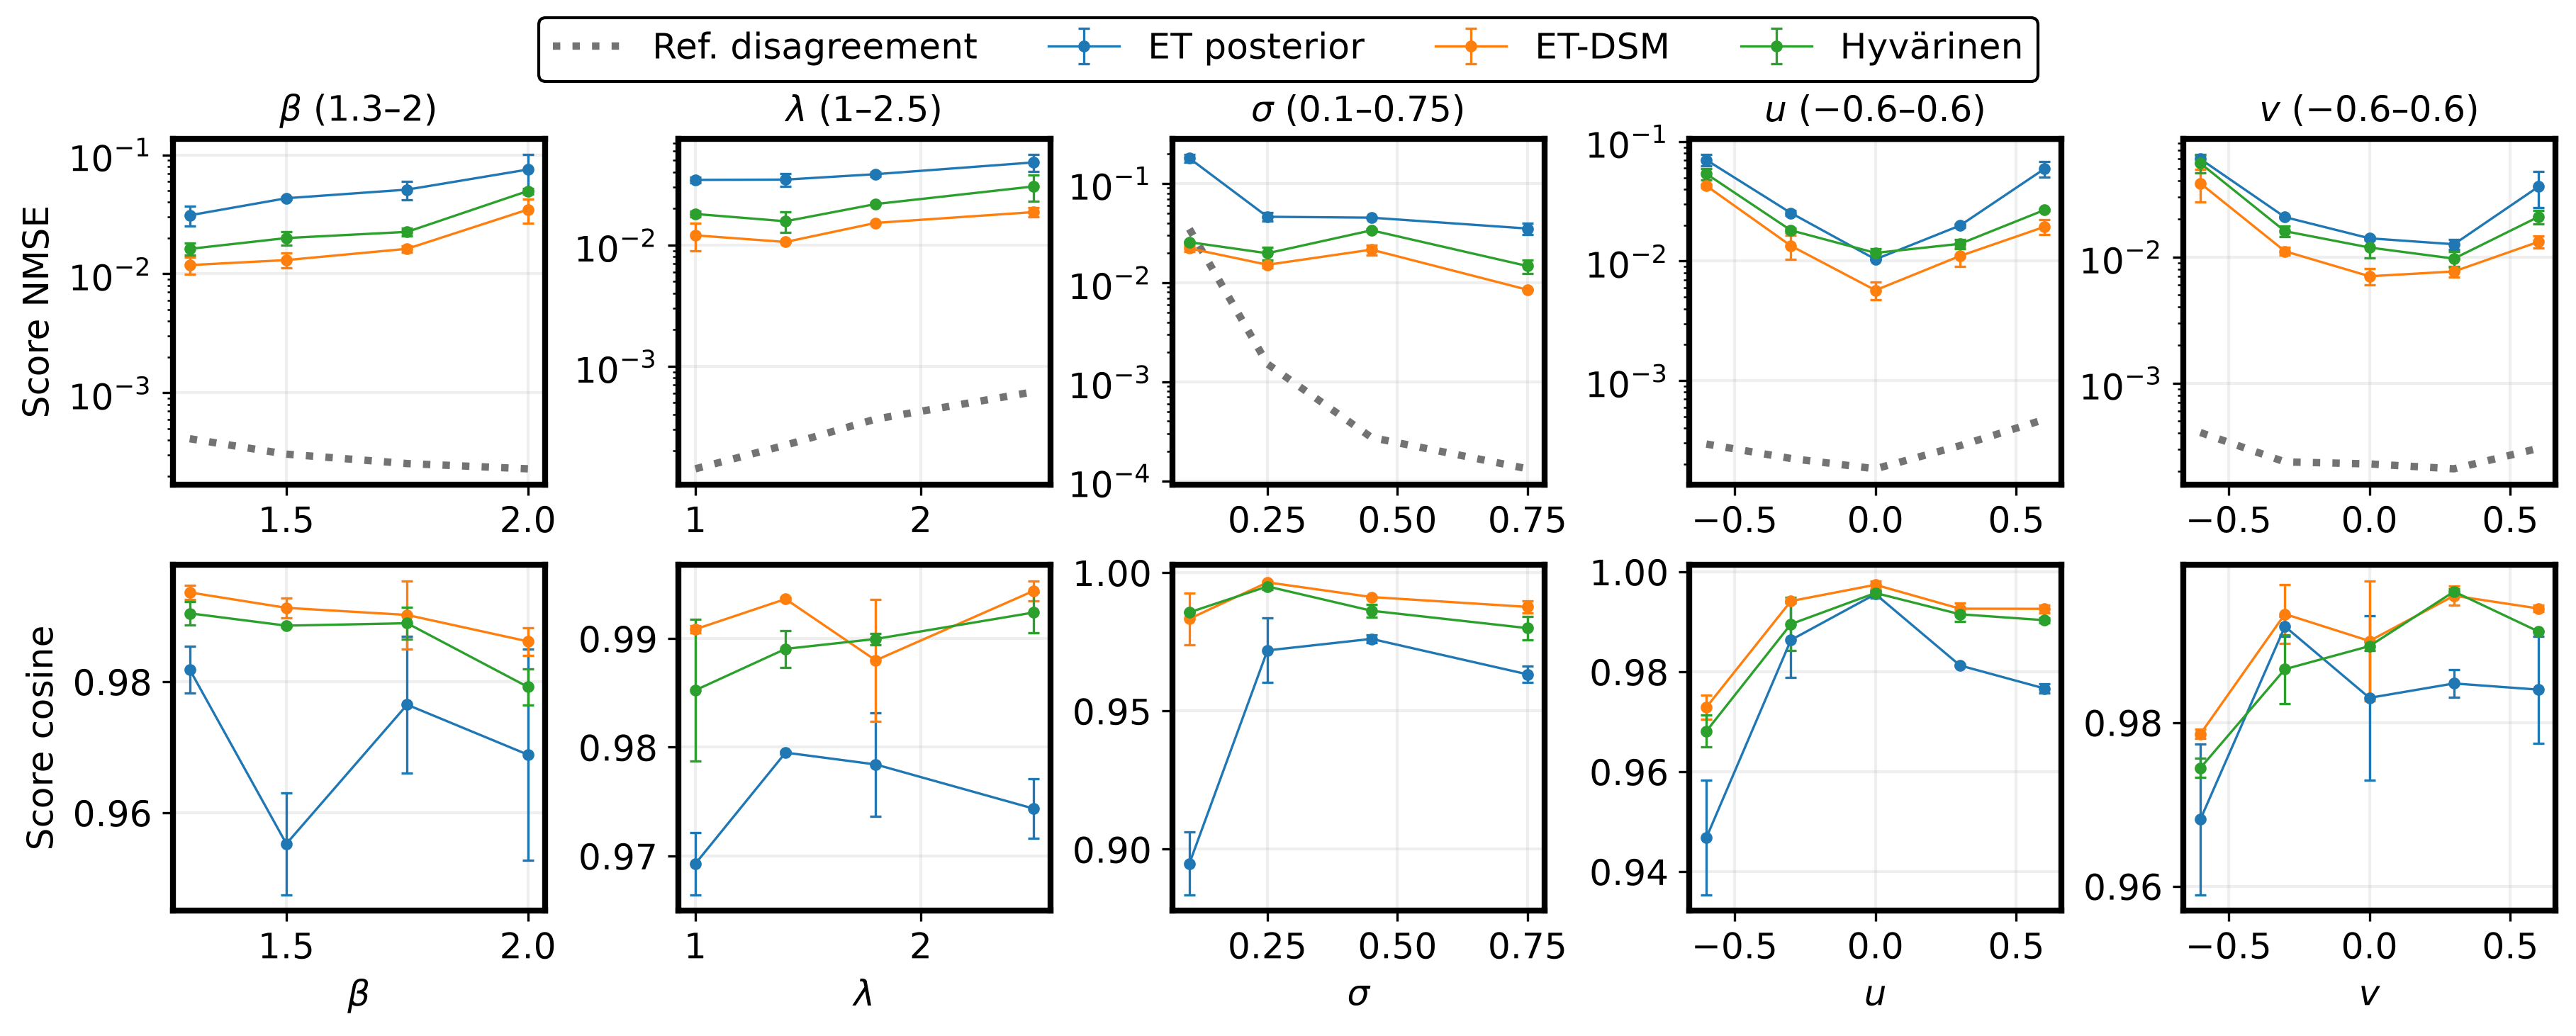

In [103]:
COMPARISON_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.close("all")
with plt.rc_context(
    {
        "font.size": 12,
        "axes.titlesize": "medium",
        "axes.labelsize": "medium",
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "legend.fontsize": "medium",
        "figure.dpi": 300,
        "savefig.dpi": 300,
    }
):
    fig, axes = plt.subplots(2, 5, figsize=(12, 4.8), constrained_layout=True)
    for column, comparison_factor in enumerate(COMPARISON_FACTORS):
        for row, (comparison_metric, ylabel) in enumerate(
            [("score_nmse", "Score NMSE"), ("score_cosine", "Score cosine")]
        ):
            ax = axes[row, column]
            for comparison_method in COMPARISON_METHODS:
                values = comparison_saved_conditions[
                    (comparison_saved_conditions.factor == comparison_factor)
                    & (comparison_saved_conditions.method == comparison_method)
                ].sort_values("factor_value")
                x = (
                    values["sigma"]
                    if comparison_factor == "rho"
                    else values["factor_value"]
                )
                ax.errorbar(
                    x,
                    values[f"{comparison_metric}_mean"],
                    yerr=values[f"{comparison_metric}_std"],
                    marker="o",
                    markersize=3,
                    capsize=2,
                    label=COMPARISON_METHOD_LABELS[comparison_method],
                    linewidth=0.8,
                    elinewidth=0.8,
                    capthick=0.8,
                )
            if row == 0:
                ref = comparison_saved_reference[
                    comparison_saved_reference.factor == comparison_factor
                ].sort_values("factor_value")
                ref_x = (
                    ref["sigma"] if comparison_factor == "rho" else ref["factor_value"]
                )
                ax.plot(
                    ref_x,
                    ref.oracle_score_split_nmse,
                    ":",
                    color="0.45",
                    label="Ref. disagreement",
                )
                ax.set_title(COMPARISON_FACTOR_LABELS[comparison_factor])
                ax.set_yscale("log")
            else:
                ax.set_xlabel(
                    COMPARISON_FACTOR_LABELS[comparison_factor].split(" (")[0]
                )
            if column == 0:
                ax.set_ylabel(ylabel)
            ax.grid(alpha=0.2)
    comparison_handles, comparison_labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        comparison_handles,
        comparison_labels,
        loc="outside upper center",
        ncol=4,
    )
    fig.savefig(
        COMPARISON_FIGURE_DIR / "score_comparison_sweeps.pdf", bbox_inches="tight"
    )
    fig.savefig(
        COMPARISON_FIGURE_DIR / "score_comparison_sweeps.png", bbox_inches="tight"
    )


**Direct-estimator training losses**

Load the optimization histories stored in the model checkpoints and compare training losses across seeds. The checkpoints are selected by `MODEL_ROOT` in the setup cell. Each objective uses the actual-RMS-squared training weight. To retrain explicitly, run `bash exp/run_score_comparison_8gauss.sh --stage train`.


In [ ]:
comparison_history_run = subprocess.run(
    [
        sys.executable,
        str(ROOT / "exp/score_comparison_8gauss.py"),
        "--stage",
        "histories",
        "--device",
        str(device),
        "--model-root",
        str(MODEL_ROOT),
    ],
    cwd=ROOT,
    check=True,
)


In [97]:
comparison_loss_config = json.loads((COMPARISON_DIR / "config.json").read_text())
COMPARISON_LOSS_WINDOW = 20
comparison_loss_parts = []
for comparison_method in ("et_dsm", "hyvarinen"):
    for comparison_seed in comparison_loss_config["seeds"]:
        comparison_history = pd.read_csv(
            COMPARISON_DIR
            / comparison_method
            / f"seed{comparison_seed}"
            / "training_history.csv"
        ).sort_values("step")
        comparison_history["method"] = comparison_method
        comparison_history["model_seed"] = comparison_seed
        comparison_history["training_pairs"] = (
            comparison_history["step"]
            * comparison_loss_config["training"]["batch_size"]
        )
        comparison_history["loss_rolling_mean"] = (
            comparison_history["loss"]
            .rolling(COMPARISON_LOSS_WINDOW, min_periods=1)
            .mean()
        )
        comparison_loss_parts.append(comparison_history)
comparison_loss_history = pd.concat(comparison_loss_parts, ignore_index=True)
COMPARISON_TABLE_DIR.mkdir(parents=True, exist_ok=True)
comparison_loss_history.to_csv(
    COMPARISON_TABLE_DIR / "score_comparison_training_history.csv", index=False
)


In [98]:
comparison_saved_loss_history = pd.read_csv(
    COMPARISON_TABLE_DIR / "score_comparison_training_history.csv"
)


**Validation population floors**

Load each objective's estimated population minimum for the eight validation conditions of each seed, using the training loss weights.

- **Hyvärinen floor:** minus half the weighted noisy-score energy, estimated from two independent numerical reference banks.
- **ET-DSM floor:** the Hyvärinen floor plus half the weighted noise-score energy. The latter has an analytic expression for the generalized-Gaussian corruption.
- **Uncertainty:** shading shows two query Monte Carlo standard errors; the saved table also reports disagreement between the reference halves. These are numerical population benchmarks, so a finite-sample validation loss can cross them.

Dashed lines mark these floors in the validation panels.

In [99]:
comparison_floor_parts = [
    pd.read_csv(
        COMPARISON_REFERENCE_DIR
        / "validation_loss_floors"
        / f"seed{comparison_seed}"
        / "floors.csv"
    )
    for comparison_seed in comparison_config["seeds"]
]
comparison_loss_floors = pd.concat(comparison_floor_parts, ignore_index=True)
COMPARISON_TABLE_DIR.mkdir(parents=True, exist_ok=True)
write_csv_atomic(
    comparison_loss_floors, COMPARISON_TABLE_DIR / "score_comparison_loss_floors.csv"
)


In [100]:
comparison_saved_loss_floors = pd.read_csv(
    COMPARISON_TABLE_DIR / "score_comparison_loss_floors.csv"
)


In [101]:
comparison_saved_loss_floors


,method,model_seed,floor,query_se,half_bank_floor_difference,max_reference_split_nmse,n_conditions,n_queries
0,et_dsm,42,0.773138,0.007869,0.000389,0.001355,8,8192
1,hyvarinen,42,-0.678984,0.007869,0.000389,0.001355,8,8192
2,et_dsm,43,0.865236,0.007932,0.000661,0.001820,8,8192
3,hyvarinen,43,-0.609804,0.007932,0.000661,0.001820,8,8192


**Final validation losses and gaps**


In [ ]:
comparison_final_validation = (
    comparison_saved_loss_history.dropna(subset=["validation_loss"])
    .sort_values("step")
    .groupby(["method", "model_seed"], as_index=False)
    .tail(1)[["method", "model_seed", "step", "validation_loss"]]
)
comparison_validation_gaps = comparison_final_validation.merge(
    comparison_saved_loss_floors[["method", "model_seed", "floor"]],
    on=["method", "model_seed"],
    validate="one_to_one",
)
comparison_score_energy_half = comparison_saved_loss_floors[
    comparison_saved_loss_floors["method"] == "hyvarinen"
][["model_seed", "floor"]].rename(columns={"floor": "hyvarinen_floor"})
comparison_validation_gaps = comparison_validation_gaps.merge(
    comparison_score_energy_half, on="model_seed", validate="many_to_one"
)
comparison_validation_gaps["relative_gap"] = (
    comparison_validation_gaps["validation_loss"] - comparison_validation_gaps["floor"]
) / (-comparison_validation_gaps["hyvarinen_floor"])
comparison_validation_gaps = comparison_validation_gaps.drop(columns="hyvarinen_floor")
write_csv_atomic(
    comparison_validation_gaps, COMPARISON_TABLE_DIR / "score_validation_gaps.csv"
)


In [ ]:
comparison_saved_validation_gaps = pd.read_csv(
    COMPARISON_TABLE_DIR / "score_validation_gaps.csv"
)


In [ ]:
comparison_saved_validation_gaps


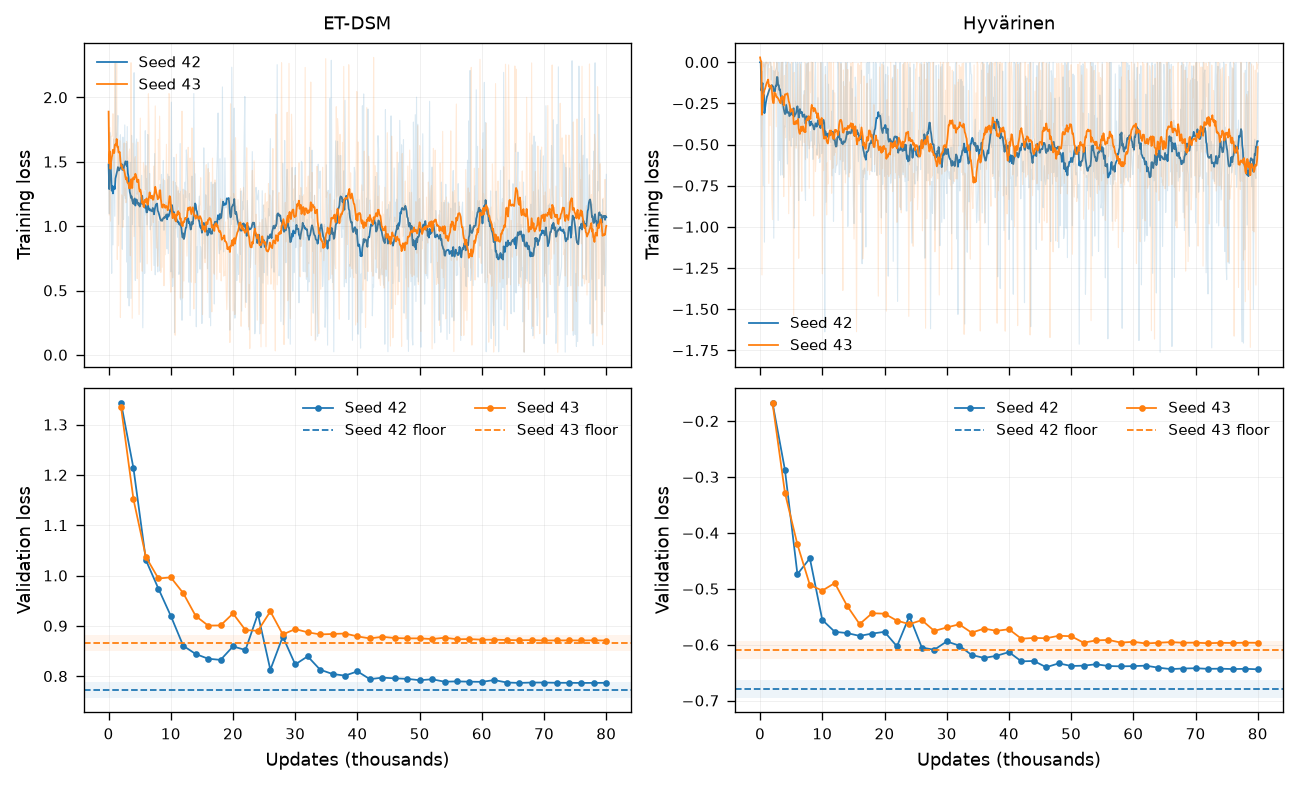

In [102]:
COMPARISON_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.close("all")
with plt.rc_context(
    {
        "font.size": 8,
        "axes.titlesize": "medium",
        "axes.labelsize": "medium",
        "xtick.labelsize": "small",
        "ytick.labelsize": "small",
        "legend.fontsize": "small",
        "axes.linewidth": 0.6,
        "lines.linewidth": 0.8,
        "grid.linewidth": 0.4,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "figure.dpi": 160,
        "savefig.dpi": 300,
    }
):
    loss_fig, loss_axes = plt.subplots(
        2, 2, figsize=(8, 4.8), sharex=True, constrained_layout=True
    )
    comparison_loss_seeds = sorted(comparison_saved_loss_history["model_seed"].unique())
    for column, comparison_method in enumerate(("et_dsm", "hyvarinen")):
        for seed_index, comparison_seed in enumerate(comparison_loss_seeds):
            history = comparison_saved_loss_history[
                (comparison_saved_loss_history["method"] == comparison_method)
                & (comparison_saved_loss_history["model_seed"] == comparison_seed)
            ].sort_values("step")
            color = f"C{seed_index}"
            label = f"Seed {comparison_seed}"
            loss_axes[0, column].plot(
                history["step"] / 1000,
                history["loss"],
                color=color,
                alpha=0.16,
                linewidth=0.5,
            )
            loss_axes[0, column].plot(
                history["step"] / 1000,
                history["loss_rolling_mean"],
                color=color,
                label=label,
            )
            validation = history.dropna(subset=["validation_loss"])
            loss_axes[1, column].plot(
                validation["step"] / 1000,
                validation["validation_loss"],
                color=color,
                marker="o",
                markersize=2,
                label=label,
            )
            floor_row = comparison_saved_loss_floors[
                (comparison_saved_loss_floors["method"] == comparison_method)
                & (comparison_saved_loss_floors["model_seed"] == comparison_seed)
            ].iloc[0]
            loss_axes[1, column].axhline(
                floor_row["floor"],
                color=color,
                linestyle="--",
                linewidth=0.8,
                label=f"Seed {comparison_seed} floor",
            )
            loss_axes[1, column].axhspan(
                floor_row["floor"] - 2 * floor_row["query_se"],
                floor_row["floor"] + 2 * floor_row["query_se"],
                color=color,
                alpha=0.08,
                linewidth=0,
            )
        loss_axes[0, column].set_title(COMPARISON_METHOD_LABELS[comparison_method])
        loss_axes[0, column].set_ylabel("Training loss")
        loss_axes[1, column].set_ylabel("Validation loss")
        loss_axes[1, column].set_xlabel("Updates (thousands)")
        loss_axes[0, column].legend(frameon=False)
        loss_axes[1, column].legend(frameon=False, ncol=2)
        for row in range(2):
            loss_axes[row, column].grid(alpha=0.2)
    loss_fig.savefig(
        COMPARISON_FIGURE_DIR / "score_comparison_training_losses.pdf",
        bbox_inches="tight",
    )
    loss_fig.savefig(
        COMPARISON_FIGURE_DIR / "score_comparison_training_losses.png",
        bbox_inches="tight",
    )


## Posterior-sample budget and noise magnitude


In [38]:
FIVE_PARAM_MC_SEED = 271828
FIVE_PARAM_MC_N_GRID = [1, 2, 4, 8, 16, 32, 64, 128, 256]
FIVE_PARAM_MC_N_REPLICATES = 10
FIVE_PARAM_MC_N_PRIOR = 160_000
FIVE_PARAM_MC_N_Y = 192
FIVE_PARAM_MC_IMPORTANCE_CHUNK = 32_768
FIVE_PARAM_MC_CONDITION = {
    "beta": 1.4,
    "lam": 1.8,
    "rho": 0.570322,
    "u": 0.0,
    "v": 0.6,
}


In [39]:
five_param_mc_beta = float(FIVE_PARAM_MC_CONDITION["beta"])
five_param_mc_lam = float(FIVE_PARAM_MC_CONDITION["lam"])
five_param_mc_rho = float(FIVE_PARAM_MC_CONDITION["rho"])
five_param_mc_uv = torch.tensor(
    [FIVE_PARAM_MC_CONDITION["u"], FIVE_PARAM_MC_CONDITION["v"]],
    device=FIVE_PARAM_DEVICE,
)
five_param_mc_Sigma = spd_2d_from_uv(five_param_mc_uv)
five_param_mc_sigma = float(
    reference_rho_to_sigma(five_param_mc_rho, five_param_mc_beta, 2)
)

set_reproducible_seed(FIVE_PARAM_MC_SEED)
five_param_mc_prior_bank = eight_gaussians(
    FIVE_PARAM_MC_N_PRIOR,
    radius=FIVE_PARAM_DATA_RADIUS,
    std=FIVE_PARAM_STD_CLEAN,
    device=FIVE_PARAM_DEVICE,
)
five_param_mc_prior_half_1, five_param_mc_prior_half_2 = torch.chunk(
    five_param_mc_prior_bank,
    2,
    dim=0,
)

set_reproducible_seed(FIVE_PARAM_MC_SEED + 1)
five_param_mc_x_clean = eight_gaussians(
    FIVE_PARAM_MC_N_Y,
    radius=FIVE_PARAM_DATA_RADIUS,
    std=FIVE_PARAM_STD_CLEAN,
    device=FIVE_PARAM_DEVICE,
)
five_param_mc_y = five_param_mc_x_clean + sample_generalized_gaussian_noise(
    FIVE_PARAM_MC_N_Y,
    beta=five_param_mc_beta,
    lam=five_param_mc_lam,
    Sigma=five_param_mc_Sigma,
    sigma=five_param_mc_sigma,
    device=FIVE_PARAM_DEVICE,
    dtype=five_param_mc_x_clean.dtype,
)

five_param_mc_oracle_1 = generalized_importance_noisy_score(
    five_param_mc_y,
    five_param_mc_prior_half_1,
    beta=five_param_mc_beta,
    lam=five_param_mc_lam,
    Sigma=five_param_mc_Sigma,
    sigma=five_param_mc_sigma,
    chunk_size=FIVE_PARAM_MC_IMPORTANCE_CHUNK,
)
five_param_mc_oracle_2 = generalized_importance_noisy_score(
    five_param_mc_y,
    five_param_mc_prior_half_2,
    beta=five_param_mc_beta,
    lam=five_param_mc_lam,
    Sigma=five_param_mc_Sigma,
    sigma=five_param_mc_sigma,
    chunk_size=FIVE_PARAM_MC_IMPORTANCE_CHUNK,
)
five_param_mc_oracle = 0.5 * (five_param_mc_oracle_1 + five_param_mc_oracle_2)
five_param_mc_oracle_power = (
    five_param_mc_oracle.square().sum(dim=1).mean().clamp_min(1e-12)
)
five_param_mc_oracle_split_nmse = float(
    (five_param_mc_oracle_1 - five_param_mc_oracle_2).square().sum(dim=1).mean()
    / five_param_mc_oracle_power
)

five_param_mc_models = [
    {
        **load_parameter_conditioned_engressor(
            FIVE_PARAM_MODEL_ROOT / spec["run_name"],
            checkpoint=spec["checkpoint"],
            device=FIVE_PARAM_DEVICE,
        ),
        "spec": spec,
    }
    for spec in FIVE_PARAM_MODEL_SPECS
]
five_param_mc_rows = []
for model_info in five_param_mc_models:
    model_seed = int(model_info["spec"]["training_seed"])
    for replicate in range(FIVE_PARAM_MC_N_REPLICATES):
        set_reproducible_seed(FIVE_PARAM_MC_SEED + 10_000 * model_seed + replicate)
        with torch.inference_mode():
            posterior = model_info["sampler"].sample(
                five_param_mc_y,
                five_param_mc_beta,
                five_param_mc_lam,
                five_param_mc_rho,
                five_param_mc_uv,
                max(FIVE_PARAM_MC_N_GRID),
            )
            for n_posterior in FIVE_PARAM_MC_N_GRID:
                score = mc_score_from_posterior_samples_spd(
                    y=five_param_mc_y,
                    x_samples=posterior[:n_posterior],
                    sigma=five_param_mc_sigma,
                    beta=five_param_mc_beta,
                    lam=five_param_mc_lam,
                    Sigma=five_param_mc_Sigma,
                )
                score_error = score - five_param_mc_oracle
                score_cosine = (score * five_param_mc_oracle).sum(dim=1) / (
                    score.norm(dim=1) * five_param_mc_oracle.norm(dim=1)
                ).clamp_min(1e-12)
                five_param_mc_rows.append(
                    {
                        "model_seed": model_seed,
                        "replicate": replicate,
                        "n_posterior": n_posterior,
                        "score_nmse": float(
                            score_error.square().sum(dim=1).mean()
                            / five_param_mc_oracle_power
                        ),
                        "score_cosine": float(score_cosine.mean()),
                    }
                )
    print(f"model seed {model_seed}: {FIVE_PARAM_MC_N_REPLICATES} replicates done")

five_param_mc_raw_df = pd.DataFrame(five_param_mc_rows)

FIVE_PARAM_MC_METRICS = ["score_nmse", "score_cosine"]
five_param_mc_per_model_df = five_param_mc_raw_df.groupby(
    ["model_seed", "n_posterior"]
)[FIVE_PARAM_MC_METRICS].agg(["mean", "std"])
five_param_mc_per_model_df.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in five_param_mc_per_model_df.columns.to_flat_index()
]
five_param_mc_per_model_df = five_param_mc_per_model_df.reset_index()

five_param_mc_summary_df = five_param_mc_raw_df.groupby("n_posterior")[
    FIVE_PARAM_MC_METRICS
].agg(["mean", "std"])
five_param_mc_summary_df.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in five_param_mc_summary_df.columns.to_flat_index()
]
five_param_mc_summary_df = five_param_mc_summary_df.reset_index()

five_param_mc_fit_rows = []
for fit_label, fit_group in [
    *five_param_mc_raw_df.groupby("model_seed"),
    ("pooled", five_param_mc_raw_df),
]:
    variance_slope, bias_floor = np.polyfit(
        1.0 / fit_group["n_posterior"].to_numpy(),
        fit_group["score_nmse"].to_numpy(),
        1,
    )
    five_param_mc_fit_rows.append(
        {
            "model": str(fit_label),
            "nmse_bias_floor": float(bias_floor),
            "nmse_variance_slope": float(variance_slope),
        }
    )
five_param_mc_fit_df = pd.DataFrame(five_param_mc_fit_rows)

five_param_mc_summary_table = pd.DataFrame(
    {
        "Posterior samples $N$": five_param_mc_summary_df["n_posterior"].astype(int),
        "Score NMSE": [
            f"{mean:.3f}  {sd:.3f}"
            for mean, sd in zip(
                five_param_mc_summary_df["score_nmse_mean"],
                five_param_mc_summary_df["score_nmse_std"],
            )
        ],
        "Score cosine": [
            f"{mean:.3f}  {sd:.3f}"
            for mean, sd in zip(
                five_param_mc_summary_df["score_cosine_mean"],
                five_param_mc_summary_df["score_cosine_std"],
            )
        ],
    }
)

write_json_atomic(
    {
        "seed": FIVE_PARAM_MC_SEED,
        "n_grid": FIVE_PARAM_MC_N_GRID,
        "n_replicates": FIVE_PARAM_MC_N_REPLICATES,
        "n_prior": FIVE_PARAM_MC_N_PRIOR,
        "n_y": FIVE_PARAM_MC_N_Y,
        "importance_chunk": FIVE_PARAM_MC_IMPORTANCE_CHUNK,
        "condition": FIVE_PARAM_MC_CONDITION,
        "models": FIVE_PARAM_MODEL_SPECS,
        "oracle_score_split_nmse": five_param_mc_oracle_split_nmse,
    },
    FIVE_PARAM_SCORE_DIR / "mc_budget_config.json",
)
write_csv_atomic(five_param_mc_raw_df, FIVE_PARAM_SCORE_DIR / "mc_budget_raw.csv")
write_csv_atomic(
    five_param_mc_per_model_df,
    FIVE_PARAM_SCORE_DIR / "mc_budget_per_model.csv",
)
write_csv_atomic(
    five_param_mc_summary_df,
    FIVE_PARAM_SCORE_DIR / "mc_budget_summary.csv",
)
write_csv_atomic(five_param_mc_fit_df, FIVE_PARAM_SCORE_DIR / "mc_budget_fit.csv")
write_csv_atomic(
    five_param_mc_summary_table,
    FIVE_PARAM_SCORE_DIR / "mc_budget_summary_table.csv",
)
five_param_mc_oracle_split_nmse


model seed 42: 10 replicates done
model seed 43: 10 replicates done


0.0002570340293459594

In [40]:
five_param_mc_raw_df = pd.read_csv(FIVE_PARAM_SCORE_DIR / "mc_budget_raw.csv")
five_param_mc_per_model_df = pd.read_csv(
    FIVE_PARAM_SCORE_DIR / "mc_budget_per_model.csv"
)
five_param_mc_summary_df = pd.read_csv(FIVE_PARAM_SCORE_DIR / "mc_budget_summary.csv")
five_param_mc_fit_df = pd.read_csv(FIVE_PARAM_SCORE_DIR / "mc_budget_fit.csv")
five_param_mc_summary_table = pd.read_csv(
    FIVE_PARAM_SCORE_DIR / "mc_budget_summary_table.csv"
)
five_param_mc_raw_df.shape


(180, 5)

In [41]:
five_param_mc_summary_table


,Posterior samples $N$,Score NMSE,Score cosine
0,1,1.446 0.110,0.574 0.039
1,2,0.698 0.061,0.681 0.034
2,4,0.368 0.052,0.780 0.041
3,8,0.196 0.018,0.856 0.025
4,16,0.112 0.012,0.909 0.016
5,32,0.071 0.010,0.938 0.013
6,64,0.050 0.008,0.961 0.009
7,128,0.039 0.006,0.973 0.007
8,256,0.034 0.006,0.980 0.005


In [42]:
five_param_mc_fit_df


,model,nmse_bias_floor,nmse_variance_slope
0,42,0.016809,1.409362
1,43,0.028706,1.405960
2,pooled,0.022757,1.407661


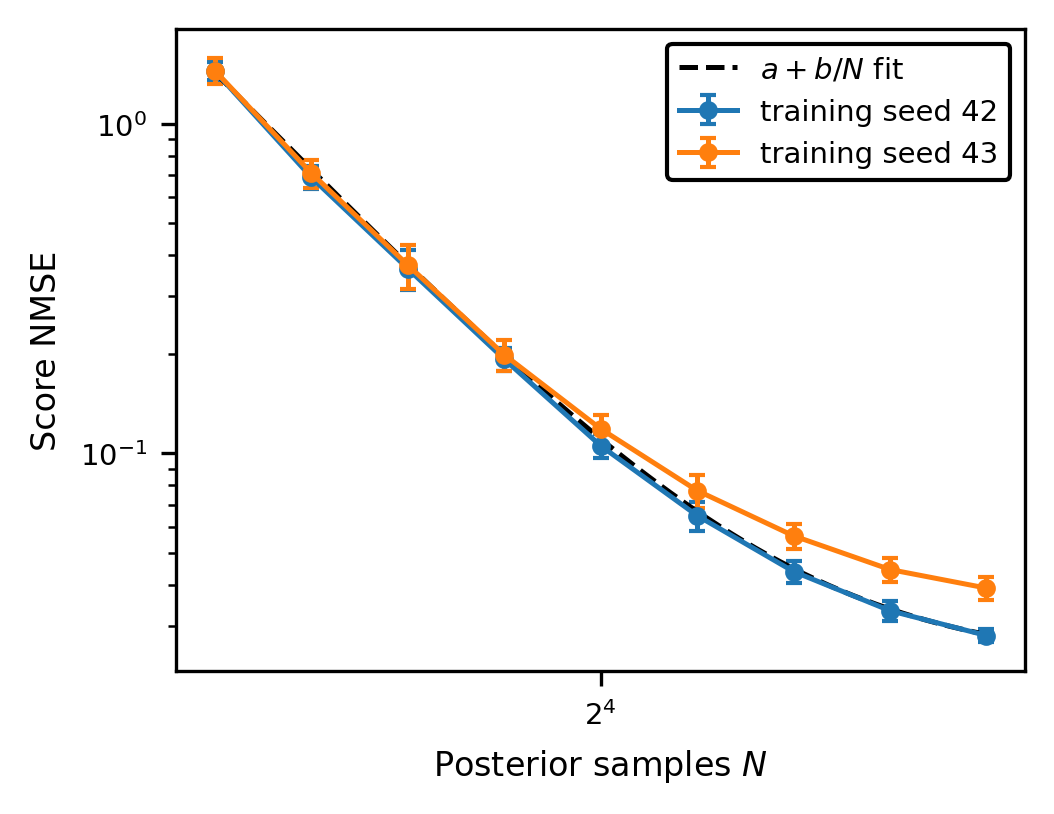

In [43]:
with plt.rc_context(FIVE_PARAM_PLOT_RC):
    fig, axis = plt.subplots(figsize=(3.4, 2.6), dpi=300)
    for model_seed, group in five_param_mc_per_model_df.groupby("model_seed"):
        axis.errorbar(
            group["n_posterior"],
            group["score_nmse_mean"],
            yerr=group["score_nmse_std"],
            marker="o",
            capsize=2,
            label=f"training seed {model_seed}",
        )
    fit_row = five_param_mc_fit_df[five_param_mc_fit_df["model"] == "pooled"].iloc[0]
    n_dense = np.geomspace(
        five_param_mc_per_model_df["n_posterior"].min(),
        five_param_mc_per_model_df["n_posterior"].max(),
        128,
    )
    axis.plot(
        n_dense,
        fit_row["nmse_bias_floor"] + fit_row["nmse_variance_slope"] / n_dense,
        linestyle="--",
        color="black",
        label=r"$a + b/N$ fit",
    )
    axis.set_xscale("log", base=2)
    axis.set_yscale("log")
    axis.set_xlabel(r"Posterior samples $N$")
    axis.set_ylabel("Score NMSE")
    axis.legend()
    fig.savefig(FIVE_PARAM_SCORE_DIR / "full5_mc_budget_nmse.png")
    fig.savefig(FIVE_PARAM_SCORE_DIR / "full5_mc_budget_nmse.pdf")


**Accuracy across noise magnitudes**

In [51]:
FIVE_PARAM_DIP_SEED = 314159
FIVE_PARAM_DIP_N_PRIOR = 160_000
FIVE_PARAM_DIP_N_Y = 192
FIVE_PARAM_DIP_N_POSTERIOR = 192
FIVE_PARAM_DIP_IMPORTANCE_CHUNK = 32_768
FIVE_PARAM_DIP_RHO_GRID = [float(rho) for rho in np.geomspace(0.02, 10.0, 16)]
FIVE_PARAM_DIP_NOISE_FAMILIES = [
    {"label": "gaussian", "beta": 2.0, "lam": 1.0},
    {"label": "generalized", "beta": 1.4, "lam": 1.8},
]


In [ ]:
five_param_dip_uv = torch.zeros(2, device=FIVE_PARAM_DEVICE)
five_param_dip_Sigma = spd_2d_from_uv(five_param_dip_uv)

set_reproducible_seed(FIVE_PARAM_DIP_SEED)
five_param_dip_prior_bank = eight_gaussians(
    FIVE_PARAM_DIP_N_PRIOR,
    radius=FIVE_PARAM_DATA_RADIUS,
    std=FIVE_PARAM_STD_CLEAN,
    device=FIVE_PARAM_DEVICE,
)
five_param_dip_prior_half_1, five_param_dip_prior_half_2 = torch.chunk(
    five_param_dip_prior_bank,
    2,
    dim=0,
)
five_param_dip_models = [
    {
        **load_parameter_conditioned_engressor(
            FIVE_PARAM_MODEL_ROOT / spec["run_name"],
            checkpoint=spec["checkpoint"],
            device=FIVE_PARAM_DEVICE,
        ),
        "spec": spec,
    }
    for spec in FIVE_PARAM_MODEL_SPECS
]

five_param_dip_rows = []
for family_index, family in enumerate(FIVE_PARAM_DIP_NOISE_FAMILIES):
    beta = float(family["beta"])
    lam = float(family["lam"])
    for rho_index, rho in enumerate(FIVE_PARAM_DIP_RHO_GRID):
        sigma = float(reference_rho_to_sigma(rho, beta, 2))
        condition_seed = (
            FIVE_PARAM_DIP_SEED + 100_000 * (family_index + 1) + 1_000 * (rho_index + 1)
        )

        set_reproducible_seed(condition_seed)
        x_clean = eight_gaussians(
            FIVE_PARAM_DIP_N_Y,
            radius=FIVE_PARAM_DATA_RADIUS,
            std=FIVE_PARAM_STD_CLEAN,
            device=FIVE_PARAM_DEVICE,
        )
        y = x_clean + sample_generalized_gaussian_noise(
            FIVE_PARAM_DIP_N_Y,
            beta=beta,
            lam=lam,
            Sigma=five_param_dip_Sigma,
            sigma=sigma,
            device=FIVE_PARAM_DEVICE,
            dtype=x_clean.dtype,
        )

        oracle_1 = generalized_importance_noisy_score(
            y,
            five_param_dip_prior_half_1,
            beta=beta,
            lam=lam,
            Sigma=five_param_dip_Sigma,
            sigma=sigma,
            chunk_size=FIVE_PARAM_DIP_IMPORTANCE_CHUNK,
        )
        oracle_2 = generalized_importance_noisy_score(
            y,
            five_param_dip_prior_half_2,
            beta=beta,
            lam=lam,
            Sigma=five_param_dip_Sigma,
            sigma=sigma,
            chunk_size=FIVE_PARAM_DIP_IMPORTANCE_CHUNK,
        )
        oracle = 0.5 * (oracle_1 + oracle_2)
        oracle_power = oracle.square().sum(dim=1).mean().clamp_min(1e-12)
        oracle_split_nmse = float(
            (oracle_1 - oracle_2).square().sum(dim=1).mean() / oracle_power
        )
        oracle_norm = oracle.norm(dim=1)
        high_norm_mask = oracle_norm >= oracle_norm.median()

        for model_info in five_param_dip_models:
            model_seed = int(model_info["spec"]["training_seed"])
            set_reproducible_seed(condition_seed + 303)
            with torch.inference_mode():
                posterior = model_info["sampler"].sample(
                    y,
                    beta,
                    lam,
                    rho,
                    five_param_dip_uv,
                    FIVE_PARAM_DIP_N_POSTERIOR,
                )
                score = mc_score_from_posterior_samples_spd(
                    y=y,
                    x_samples=posterior,
                    sigma=sigma,
                    beta=beta,
                    lam=lam,
                    Sigma=five_param_dip_Sigma,
                )
            score_cosine = (score * oracle).sum(dim=1) / (
                score.norm(dim=1) * oracle_norm
            ).clamp_min(1e-12)
            five_param_dip_rows.append(
                {
                    "family": family["label"],
                    "beta": beta,
                    "lambda": lam,
                    "rho": rho,
                    "sigma": sigma,
                    "actual_rms": float(
                        generalized_gaussian_actual_rms(rho, beta, lam)
                    ),
                    "model_seed": model_seed,
                    "score_nmse": float(
                        (score - oracle).square().sum(dim=1).mean() / oracle_power
                    ),
                    "cosine_all": float(score_cosine.mean()),
                    "cosine_high_norm": float(score_cosine[high_norm_mask].mean()),
                    "cosine_low_norm": float(score_cosine[~high_norm_mask].mean()),
                    "oracle_split_nmse": oracle_split_nmse,
                }
            )
        print(f"{family['label']} rho={rho:.3f} (sigma={sigma:.3f}) done")

five_param_dip_raw_df = pd.DataFrame(five_param_dip_rows)

FIVE_PARAM_DIP_METRICS = [
    "score_nmse",
    "cosine_all",
    "cosine_high_norm",
    "cosine_low_norm",
]
five_param_dip_summary_df = five_param_dip_raw_df.groupby(
    ["family", "beta", "lambda", "rho", "sigma", "actual_rms", "oracle_split_nmse"]
)[FIVE_PARAM_DIP_METRICS].agg(["mean", "std"])
five_param_dip_summary_df.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in five_param_dip_summary_df.columns.to_flat_index()
]
five_param_dip_summary_df = five_param_dip_summary_df.reset_index().sort_values(
    ["family", "rho"]
)

write_json_atomic(
    {
        "seed": FIVE_PARAM_DIP_SEED,
        "n_prior": FIVE_PARAM_DIP_N_PRIOR,
        "n_y": FIVE_PARAM_DIP_N_Y,
        "n_posterior": FIVE_PARAM_DIP_N_POSTERIOR,
        "importance_chunk": FIVE_PARAM_DIP_IMPORTANCE_CHUNK,
        "rho_grid": FIVE_PARAM_DIP_RHO_GRID,
        "noise_families": FIVE_PARAM_DIP_NOISE_FAMILIES,
        "models": FIVE_PARAM_MODEL_SPECS,
    },
    FIVE_PARAM_SCORE_DIR / "cosine_dip_config.json",
)
write_csv_atomic(five_param_dip_raw_df, FIVE_PARAM_SCORE_DIR / "cosine_dip_raw.csv")
write_csv_atomic(
    five_param_dip_summary_df,
    FIVE_PARAM_SCORE_DIR / "cosine_dip_summary.csv",
)
five_param_dip_raw_df.shape


In [54]:
five_param_dip_raw_df = pd.read_csv(FIVE_PARAM_SCORE_DIR / "cosine_dip_raw.csv")
five_param_dip_summary_df = pd.read_csv(FIVE_PARAM_SCORE_DIR / "cosine_dip_summary.csv")
five_param_dip_summary_df.shape


(32, 15)

In [55]:
five_param_dip_summary_df


,family,beta,lambda,rho,sigma,actual_rms,oracle_split_nmse,score_nmse_mean,score_nmse_std,cosine_all_mean,cosine_all_std,cosine_high_norm_mean,cosine_high_norm_std,cosine_low_norm_mean,cosine_low_norm_std
0,gaussian,2.0,1.0,0.020000,0.020000,0.020000,1.097249e+00,1.557392,0.190247,0.344597,0.082044,0.465550,0.070536,0.221097,0.093794
1,gaussian,2.0,1.0,0.030266,0.030266,0.030266,1.541606e+00,0.783312,0.109758,0.655190,0.023326,0.825558,0.010405,0.481234,0.036518
2,gaussian,2.0,1.0,0.045803,0.045803,0.045803,1.362846e-01,0.268635,0.018007,0.813836,0.050110,0.934081,0.022808,0.691061,0.077987
3,gaussian,2.0,1.0,0.069314,0.069314,0.069314,2.090830e-02,0.098801,0.007588,0.911934,0.019892,0.985033,0.003214,0.837296,0.036921
4,gaussian,2.0,1.0,0.104895,0.104895,0.104895,3.870207e-03,0.072124,0.005452,0.968486,0.004953,0.990581,0.000571,0.945926,0.009427
5,gaussian,2.0,1.0,0.158740,0.158740,0.158740,1.367918e-03,0.053313,0.001601,0.980670,0.002781,0.991158,0.001354,0.969962,0.007004
6,gaussian,2.0,1.0,0.240225,0.240225,0.240225,3.637499e-04,0.036931,0.002177,0.993032,0.001294,0.992716,0.001174,0.993354,0.001417
7,gaussian,2.0,1.0,0.363538,0.363538,0.363538,1.374101e-04,0.025084,0.003676,0.983736,0.000131,0.991762,0.000852,0.975541,0.001134
8,gaussian,2.0,1.0,0.550149,0.550149,0.550149,5.852722e-05,0.016405,0.001071,0.986182,0.001551,0.995747,0.000311,0.976415,0.003452
9,gaussian,2.0,1.0,0.832553,0.832553,0.832553,3.808970e-05,0.016040,0.003241,0.945707,0.003341,0.994314,0.001504,0.896077,0.005217


In [ ]:
with plt.rc_context(
    {
        **FIVE_PARAM_PLOT_RC,
        "font.size": 6.5,
        "axes.titlesize": 7,
        "axes.labelsize": 6.5,
        "xtick.labelsize": 5.5,
        "ytick.labelsize": 5.5,
        "legend.fontsize": 5.5,
        "lines.linewidth": 0.9,
        "lines.markersize": 2.6,
        "axes.linewidth": 0.7,
        "savefig.pad_inches": 0.02,
    }
):
    fig, axes = plt.subplots(
        1,
        4,
        figsize=(7.1, 1.95),
        dpi=300,
        constrained_layout=True,
    )
    axes[1].sharey(axes[0])
    axes[3].sharey(axes[2])

    for family_index, family in enumerate(
        [family["label"] for family in FIVE_PARAM_DIP_NOISE_FAMILIES]
    ):
        family_summary = five_param_dip_summary_df[
            five_param_dip_summary_df["family"] == family
        ].sort_values("sigma")
        cosine_axis = axes[family_index]
        nmse_axis = axes[family_index + 2]

        for column, style, label in [
            ("cosine_all", "-", "all points"),
            ("cosine_high_norm", "--", "high ref. norm"),
            ("cosine_low_norm", ":", "low ref. norm"),
        ]:
            cosine_axis.errorbar(
                family_summary["sigma"],
                family_summary[f"{column}_mean"],
                yerr=family_summary[f"{column}_std"],
                linestyle=style,
                marker="o",
                capsize=1.5,
                label=label,
            )

        nmse_axis.errorbar(
            family_summary["sigma"],
            family_summary["score_nmse_mean"],
            yerr=family_summary["score_nmse_std"],
            linestyle="-",
            marker="o",
            capsize=1.5,
            label="score NMSE",
        )

        reference_limited = family_summary[family_summary["oracle_split_nmse"] > 0.01]
        if len(reference_limited):
            for axis in (cosine_axis, nmse_axis):
                axis.axvspan(
                    reference_limited["sigma"].min(),
                    reference_limited["sigma"].max(),
                    color="gray",
                    alpha=0.15,
                )

        for axis in (cosine_axis, nmse_axis):
            axis.set_xscale("log")
            axis.set_xlabel(r"$\sigma$")
            axis.set_title(family.capitalize())
        nmse_axis.set_yscale("log")

    axes[0].set_ylabel("Score cosine")
    axes[2].set_ylabel("Score NMSE")
    axes[0].legend(loc="lower right")
    axes[2].legend(loc="upper right")

    fig.savefig(FIVE_PARAM_SCORE_DIR / "full5_score_diagnostics.png")
    fig.savefig(FIVE_PARAM_SCORE_DIR / "full5_score_diagnostics.pdf")


**Exact-posterior control**

Replace the learned posterior by draws from the true posterior and apply the same Monte Carlo score estimator with $N=192$ draws per observation. Error from the learned posterior model is then absent, while the Monte Carlo error of the finite-$N$ estimate remains.

- **Gaussian noise:** the Eight-Gaussians posterior is a Gaussian mixture with analytic weights and component means, so the average of $N$ exact posterior draws can be sampled directly and passed through Tweedie's formula. The reference is the analytic noisy score.
- **Generalized Gaussian noise:** $N$ draws are resampled from importance weights on a bank of clean samples and averaged in the conditional noise score. The reference is the importance-weighted score on the same bank, so the comparison measures finite-$N$ sampling error alone.

The table compares the controls with the learned-posterior values at the dip, the grid point with the lowest mean cosine among those whose split oracle NMSE is at most $0.01$.

In [ ]:
FIVE_PARAM_DIP_CONTROL_N_POSTERIOR = 192
FIVE_PARAM_DIP_CONTROL_N_COMPONENTS = 8
FIVE_PARAM_DIP_CONTROL_GAUSSIAN_N_Y = 200_000
FIVE_PARAM_DIP_CONTROL_GAUSSIAN_SIGMAS = [
    10.0,
    4.366539,
    2.8854,
    1.906666,
    1.259921,
    0.832553,
    0.550149,
    0.363538,
    0.240225,
    0.158740,
]
FIVE_PARAM_DIP_CONTROL_GENERALIZED_N_Y = 2_000
FIVE_PARAM_DIP_CONTROL_GENERALIZED_N_BANK = 80_000
FIVE_PARAM_DIP_CONTROL_GENERALIZED_BATCH = 40
FIVE_PARAM_DIP_CONTROL_GENERALIZED_SIGMAS = [0.994113, 1.504413, 2.276661, 3.445321]


def five_param_dip_control_metrics(reference, score):
    reference_norm = np.linalg.norm(reference, axis=1)
    score_norm = np.linalg.norm(score, axis=1)
    cosine = np.sum(reference * score, axis=1) / (reference_norm * score_norm + 1e-12)
    high_norm = reference_norm >= np.median(reference_norm)
    power = np.mean(np.sum(reference * reference, axis=1))
    return {
        "score_nmse": float(np.mean(np.sum((score - reference) ** 2, axis=1)) / power),
        "cosine_all": float(cosine.mean()),
        "cosine_high_norm": float(cosine[high_norm].mean()),
        "cosine_low_norm": float(cosine[~high_norm].mean()),
        "reference_rms": float(np.sqrt(power)),
    }


In [ ]:
five_param_dip_control_rows = []
n_components = FIVE_PARAM_DIP_CONTROL_N_COMPONENTS
n_posterior = FIVE_PARAM_DIP_CONTROL_N_POSTERIOR
tau = FIVE_PARAM_STD_CLEAN


gaussian = next(f for f in FIVE_PARAM_DIP_NOISE_FAMILIES if f["label"] == "gaussian")
n_y = FIVE_PARAM_DIP_CONTROL_GAUSSIAN_N_Y
rng = np.random.default_rng(FIVE_PARAM_DIP_SEED)
angles = np.arange(n_components) * 2 * np.pi / n_components
means = FIVE_PARAM_DATA_RADIUS * np.c_[np.cos(angles), np.sin(angles)]
for sigma in FIVE_PARAM_DIP_CONTROL_GAUSSIAN_SIGMAS:
    component = rng.integers(n_components, size=n_y)
    x_clean = means[component] + rng.normal(scale=tau, size=(n_y, 2))
    y = x_clean + rng.normal(scale=sigma, size=(n_y, 2))
    marginal_var = tau * tau + sigma * sigma
    residual = y[:, None, :] - means[None, :, :]
    log_resp = -0.5 * np.sum(residual * residual, axis=2) / marginal_var
    log_resp -= log_resp.max(1, keepdims=True)
    resp = np.exp(log_resp)
    resp /= resp.sum(1, keepdims=True)
    component_mean = (
        tau * tau * y[:, None, :] + sigma * sigma * means[None, :, :]
    ) / marginal_var
    reference = (np.sum(resp[:, :, None] * component_mean, axis=1) - y) / (
        sigma * sigma
    )

    counts = rng.multinomial(n_posterior, resp)
    draw_mean = np.sum(counts[:, :, None] * component_mean, axis=1) / n_posterior
    within_var = tau * tau * sigma * sigma / marginal_var
    draw_mean += rng.normal(scale=np.sqrt(within_var / n_posterior), size=(n_y, 2))
    score = (draw_mean - y) / (sigma * sigma)
    five_param_dip_control_rows.append(
        {
            "family": "gaussian",
            "beta": gaussian["beta"],
            "lambda": gaussian["lam"],
            "sigma": sigma,
            "posterior": "exact",
            "n_y": n_y,
            "n_posterior": n_posterior,
            **five_param_dip_control_metrics(reference, score),
        }
    )
    print(f"gaussian sigma={sigma:.4f} done")


generalized = next(
    f for f in FIVE_PARAM_DIP_NOISE_FAMILIES if f["label"] == "generalized"
)
beta, lam = float(generalized["beta"]), float(generalized["lam"])
n_y = FIVE_PARAM_DIP_CONTROL_GENERALIZED_N_Y
n_bank = FIVE_PARAM_DIP_CONTROL_GENERALIZED_N_BANK
batch = FIVE_PARAM_DIP_CONTROL_GENERALIZED_BATCH
rng = np.random.default_rng(FIVE_PARAM_DIP_SEED)
angles = np.arange(n_components, dtype=np.float32) * np.float32(
    2 * np.pi / n_components
)
means = (FIVE_PARAM_DATA_RADIUS * np.c_[np.cos(angles), np.sin(angles)]).astype(
    np.float32
)
component = rng.integers(n_components, size=n_bank)
bank = means[component] + rng.normal(scale=tau, size=(n_bank, 2)).astype(np.float32)
for sigma in FIVE_PARAM_DIP_CONTROL_GENERALIZED_SIGMAS:
    component = rng.integers(n_components, size=n_y)
    x_clean = means[component] + rng.normal(scale=tau, size=(n_y, 2)).astype(np.float32)

    direction = rng.normal(size=(n_y, 2)).astype(np.float32)
    direction /= np.linalg.norm(direction, axis=1, keepdims=True).clip(min=1e-12)
    gamma = rng.gamma(shape=2 / beta, scale=1, size=n_y).astype(np.float32)
    radius = np.float32(sigma * (beta / lam) ** (1 / beta)) * gamma ** np.float32(
        1 / beta
    )
    y = x_clean + direction * radius[:, None]
    reference = np.empty_like(y)
    score = np.empty_like(y)
    for start in range(0, n_y, batch):
        y_batch = y[start : start + batch]
        residual = y_batch[:, None, :] - bank[None, :, :]
        scaled_radius = np.maximum(
            np.linalg.norm(residual, axis=2) / np.float32(sigma), np.float32(1e-10)
        )
        log_w = -np.float32(lam / beta) * scaled_radius ** np.float32(beta)
        log_w -= log_w.max(axis=1, keepdims=True)
        w = np.exp(log_w)
        w /= w.sum(axis=1, keepdims=True)
        noise_score = (
            -np.float32(lam / (sigma * sigma))
            * scaled_radius[:, :, None] ** np.float32(beta - 2)
            * residual
        )
        reference[start : start + len(y_batch)] = np.sum(
            w[:, :, None] * noise_score, axis=1
        )
        for j in range(len(y_batch)):
            draws = rng.choice(n_bank, size=n_posterior, replace=True, p=w[j])
            score[start + j] = noise_score[j, draws].mean(axis=0)
    five_param_dip_control_rows.append(
        {
            "family": "generalized",
            "beta": beta,
            "lambda": lam,
            "sigma": sigma,
            "posterior": "importance-sampled",
            "n_y": n_y,
            "n_posterior": n_posterior,
            **five_param_dip_control_metrics(reference, score),
        }
    )
    print(f"generalized sigma={sigma:.4f} done")

write_csv_atomic(
    pd.DataFrame(five_param_dip_control_rows),
    FIVE_PARAM_SCORE_DIR / "cosine_dip_control.csv",
)
write_json_atomic(
    {
        "seed": FIVE_PARAM_DIP_SEED,
        "radius": FIVE_PARAM_DATA_RADIUS,
        "std_clean": FIVE_PARAM_STD_CLEAN,
        "n_posterior": FIVE_PARAM_DIP_CONTROL_N_POSTERIOR,
        "gaussian": {
            "n_y": FIVE_PARAM_DIP_CONTROL_GAUSSIAN_N_Y,
            "sigmas": FIVE_PARAM_DIP_CONTROL_GAUSSIAN_SIGMAS,
        },
        "generalized": {
            "beta": beta,
            "lam": lam,
            "n_y": FIVE_PARAM_DIP_CONTROL_GENERALIZED_N_Y,
            "n_bank": FIVE_PARAM_DIP_CONTROL_GENERALIZED_N_BANK,
            "sigmas": FIVE_PARAM_DIP_CONTROL_GENERALIZED_SIGMAS,
        },
    },
    FIVE_PARAM_SCORE_DIR / "cosine_dip_control_config.json",
)


In [ ]:
five_param_dip_control_df = pd.read_csv(FIVE_PARAM_SCORE_DIR / "cosine_dip_control.csv")

five_param_dip_control_table_rows = []
for family in FIVE_PARAM_DIP_NOISE_FAMILIES:
    learned = five_param_dip_summary_df[
        (five_param_dip_summary_df["family"] == family["label"])
        & (five_param_dip_summary_df["oracle_split_nmse"] <= 0.01)
    ]
    dip = learned.loc[learned["cosine_all_mean"].idxmin()]
    control = five_param_dip_control_df[
        (five_param_dip_control_df["family"] == family["label"])
        & np.isclose(five_param_dip_control_df["sigma"], dip["sigma"], atol=1e-5)
    ]
    if len(control) != 1:
        raise ValueError(
            f"No control at the {family['label']} dip, sigma={dip['sigma']:.6f}"
        )
    control = control.iloc[0]
    noise = f"{family['label'].capitalize()}, sigma={dip['sigma']:.3f}"
    five_param_dip_control_table_rows.append(
        {
            "noise": noise,
            "posterior": "learned",
            **{
                m: dip[f"{m}_mean"]
                for m in [
                    "score_nmse",
                    "cosine_all",
                    "cosine_high_norm",
                    "cosine_low_norm",
                ]
            },
        }
    )
    five_param_dip_control_table_rows.append(
        {
            "noise": noise,
            "posterior": control["posterior"],
            **{
                m: control[m]
                for m in [
                    "score_nmse",
                    "cosine_all",
                    "cosine_high_norm",
                    "cosine_low_norm",
                ]
            },
        }
    )
five_param_dip_control_table = pd.DataFrame(five_param_dip_control_table_rows)
write_csv_atomic(
    five_param_dip_control_table, FIVE_PARAM_SCORE_DIR / "cosine_dip_control_table.csv"
)


In [ ]:
five_param_dip_control_table = pd.read_csv(
    FIVE_PARAM_SCORE_DIR / "cosine_dip_control_table.csv"
)


In [ ]:
five_param_dip_control_table


## Richardson clean-score fields

For each isotropic posterior model, adjacent pairs on a 20-point training-range noise grid are compared with the analytic clean score. The pair with the lowest clean-score MSE supplies the clean-score and residual plots. The generating cells save summaries; the following cells reload them to draw the figures.

**Gaussian posterior**

In [32]:
model_name = "gaussian_isotropic"


In [33]:
model_dir = MODEL_ROOT / "score_and_diffusion" / model_name
config = omegaconf.OmegaConf.load(f"{model_dir}/config.yaml")
hash = model_name


In [34]:
engressor = torch.load(f"{model_dir}/model.pt", weights_only=False)
engressor.model = engressor.model.to(device)
eng_sampler = EngressorSampler(engressor, device, log_sigma=True)
sampling_fn = eng_sampler.sample


In [35]:
radius = config.data.radius
std_clean = config.data.std_clean


In [45]:
n_sigma_sweep = 20
sigma_min = config.noise.sigma_min
sigma_max = config.noise.sigma_max

sigmas = np.geomspace(sigma_max, sigma_min, num=n_sigma_sweep).astype(float)


sigma1 = float(sigmas[-5])
sigma2 = float(sigmas[-6])

print(f"Using sigma1={sigma1:.4g}, sigma2={sigma2:.4g} for Richardson extrapolation")

n_grid = 35
n_mc = 1280


Using sigma1=0.04281, sigma2=0.06158 for Richardson extrapolation


In [46]:
best = (0, 0, 1e10)


In [47]:
for sigma1, sigma2 in zip(sigmas[1:], sigmas[:-1]):
    print(f"Sigma pair: {sigma1:.4g}, {sigma2:.4g}")

    out1 = compute_noisy_score_mse_grid(
        posterior_sampler_fn=sampling_fn,
        sigma=sigma1,
        std_clean=std_clean,
        radius=radius,
        n_grid=n_grid,
        n_mc=n_mc,
        device=device,
    )
    out2 = compute_noisy_score_mse_grid(
        posterior_sampler_fn=sampling_fn,
        sigma=sigma2,
        std_clean=std_clean,
        radius=radius,
        n_grid=n_grid,
        n_mc=n_mc,
        device=device,
    )

    grid = out1["grid"].to(device)
    s1_hat = out1["s_hat"].to(device)
    s2_hat = out2["s_hat"].to(device)

    assert torch.allclose(
        grid, out2["grid"].to(device)
    ), "Grid mismatch between sigma1 and sigma2"

    s_clean_hat = richardson_extrapolate(s1_hat, s2_hat, sigma1=sigma1, sigma2=sigma2)

    s_clean_true = eight_gaussians_score(
        grid,
        radius=radius,
        std=std_clean,
        device=device,
    )

    s_clean_hat_cpu = s_clean_hat.detach().cpu()
    s_clean_true_cpu = s_clean_true.detach().cpu()
    s1_hat_cpu = s1_hat.detach().cpu()
    s2_hat_cpu = s2_hat.detach().cpu()
    grid_cpu = grid.detach().cpu()

    mse_clean = float(((s_clean_hat_cpu - s_clean_true_cpu) ** 2).mean())

    mse_sigma1_clean = float(((s1_hat_cpu - s_clean_true_cpu) ** 2).mean())
    mse_sigma2_clean = float(((s2_hat_cpu - s_clean_true_cpu) ** 2).mean())

    print(f"Clean-score MSE (Richardson): {mse_clean:.6e}")
    print(f"Clean-score MSE at sigma1={sigma1:.4g}: {mse_sigma1_clean:.6e}")
    print(f"Clean-score MSE at sigma2={sigma2:.4g}: {mse_sigma2_clean:.6e}")

    if mse_clean < best[2]:
        best = (sigma1, sigma2, mse_clean)
        print(f"  New best pair found.")

        res = {
            "model_dir": model_dir,
            "model_name": model_name,
            "model_hash": hash,
            "radius": radius,
            "std_clean": std_clean,
            "sigma1": sigma1,
            "sigma2": sigma2,
            "n_grid": n_grid,
            "n_mc": n_mc,
            "mse_clean": mse_clean,
            "mse_sigma1_clean": mse_sigma1_clean,
            "mse_sigma2_clean": mse_sigma2_clean,
            "grid": grid_cpu.numpy(),
            "s_clean_hat": s_clean_hat_cpu.numpy(),
            "s_clean_true": s_clean_true_cpu.numpy(),
            "s_hat_sigma1": s1_hat_cpu.numpy(),
            "s_hat_sigma2": s2_hat_cpu.numpy(),
            "noisy_mse_sigma1": float(out1["mse"]),
            "noisy_mse_sigma2": float(out2["mse"]),
        }


Sigma pair: 6.952, 10
Clean-score MSE (Richardson): 9.190278e+02
Clean-score MSE at sigma1=6.952: 9.202151e+02
Clean-score MSE at sigma2=10: 9.214856e+02
  New best pair found.
Sigma pair: 4.833, 6.952
Clean-score MSE (Richardson): 9.154219e+02
Clean-score MSE at sigma1=4.833: 9.177365e+02
Clean-score MSE at sigma2=6.952: 9.202152e+02
  New best pair found.
Sigma pair: 3.36, 4.833
Clean-score MSE (Richardson): 9.092020e+02
Clean-score MSE at sigma1=3.36: 9.133196e+02
Clean-score MSE at sigma2=4.833: 9.177349e+02
  New best pair found.
Sigma pair: 2.336, 3.36
Clean-score MSE (Richardson): 8.995259e+02
Clean-score MSE at sigma1=2.336: 9.061750e+02
Clean-score MSE at sigma2=3.36: 9.133170e+02
  New best pair found.
Sigma pair: 1.624, 2.336
Clean-score MSE (Richardson): 8.826692e+02
Clean-score MSE at sigma1=1.624: 8.939844e+02
Clean-score MSE at sigma2=2.336: 9.061712e+02
  New best pair found.
Sigma pair: 1.129, 1.624
Clean-score MSE (Richardson): 8.462239e+02
Clean-score MSE at sigma1=1

In [49]:
out_path = os.path.join("res/8gauss/score/gaussian_richardson_summary2.joblib")
os.makedirs(os.path.dirname(out_path), exist_ok=True)

joblib.dump(
    res,
    out_path,
)

print(f"Saved Richardson summary to {out_path}")


Saved Richardson summary to res/8gauss/score/gaussian_richardson_summary2.joblib


In [ ]:
res = joblib.load("res/8gauss/score/gaussian_richardson_summary2.joblib")


**Generalized Gaussian posterior**

In [52]:
model_name = "generalized_isotropic"


In [53]:
model_dir = MODEL_ROOT / "score_and_diffusion" / model_name
config = omegaconf.OmegaConf.load(f"{model_dir}/config.yaml")
hash = model_name


In [54]:
engressor = torch.load(f"{model_dir}/model.pt", weights_only=False)
engressor.model = engressor.model.to(device)
eng_sampler = EngressorSampler(engressor, device, log_sigma=True)
sampling_fn = eng_sampler.sample


In [55]:
radius = config.data.radius
std_clean = config.data.std_clean
beta_noise = config.generalized.beta_noise
lam = config.generalized.lam


In [56]:
print(f"Using generalized noise: beta_noise={beta_noise}, lam={lam}")


n_sigma_sweep = 20
sigma_min = float(config.noise.sigma_min)
sigma_max = float(config.noise.sigma_max)

sigmas = np.geomspace(sigma_max, sigma_min, num=n_sigma_sweep).astype(float)

print(f"Sigma range: [{sigma_min:.4g}, {sigma_max:.4g}] with {n_sigma_sweep} points")

n_grid = 35
n_mc = 1280
n_prior_mc = 8192


Using generalized noise: beta_noise=1.4, lam=1.8
Sigma range: [0.01, 10] with 20 points


In [57]:
best = (0.0, 0.0, 1e10)
res = None


for sigma1, sigma2 in zip(sigmas[1:], sigmas[:-1]):
    sigma1 = float(sigma1)
    sigma2 = float(sigma2)
    print(f"\nSigma pair: {sigma1:.4g}, {sigma2:.4g}")

    out1 = compute_noisy_score_mse_grid_generalized(
        posterior_sampler_fn=sampling_fn,
        sigma=sigma1,
        std_clean=std_clean,
        radius=radius,
        beta=beta_noise,
        lam=lam,
        n_grid=n_grid,
        n_mc=n_mc,
        n_prior_mc=n_prior_mc,
        device=device,
    )
    out2 = compute_noisy_score_mse_grid_generalized(
        posterior_sampler_fn=sampling_fn,
        sigma=sigma2,
        std_clean=std_clean,
        radius=radius,
        beta=beta_noise,
        lam=lam,
        n_grid=n_grid,
        n_mc=n_mc,
        n_prior_mc=n_prior_mc,
        device=device,
    )

    grid = out1["grid"].to(device)
    s1_hat = out1["s_hat"].to(device)
    s2_hat = out2["s_hat"].to(device)

    assert torch.allclose(
        grid, out2["grid"].to(device)
    ), "Grid mismatch between sigma1 and sigma2"

    s_clean_hat = richardson_extrapolate(s1_hat, s2_hat, sigma1=sigma1, sigma2=sigma2)

    s_clean_true = eight_gaussians_score(
        grid,
        radius=radius,
        std=std_clean,
        device=device,
    )

    s_clean_hat_cpu = s_clean_hat.detach().cpu()
    s_clean_true_cpu = s_clean_true.detach().cpu()
    s1_hat_cpu = s1_hat.detach().cpu()
    s2_hat_cpu = s2_hat.detach().cpu()
    grid_cpu = grid.detach().cpu()

    mse_clean = float(((s_clean_hat_cpu - s_clean_true_cpu) ** 2).mean())

    mse_sigma1_clean = float(((s1_hat_cpu - s_clean_true_cpu) ** 2).mean())
    mse_sigma2_clean = float(((s2_hat_cpu - s_clean_true_cpu) ** 2).mean())

    print(f"  Clean-score MSE (Richardson): {mse_clean:.6e}")
    print(f"  Clean-score MSE at sigma1={sigma1:.4g}: {mse_sigma1_clean:.6e}")
    print(f"  Clean-score MSE at sigma2={sigma2:.4g}: {mse_sigma2_clean:.6e}")

    if mse_clean < best[2]:
        best = (sigma1, sigma2, mse_clean)
        print("  New best pair found.")

        res = {
            "model_dir": model_dir,
            "model_name": model_name,
            "model_hash": hash,
            "radius": radius,
            "std_clean": std_clean,
            "beta_noise": beta_noise,
            "lam": lam,
            "sigma1": sigma1,
            "sigma2": sigma2,
            "n_grid": n_grid,
            "n_mc": n_mc,
            "n_prior_mc": n_prior_mc,
            "mse_clean": mse_clean,
            "mse_sigma1_clean": mse_sigma1_clean,
            "mse_sigma2_clean": mse_sigma2_clean,
            "grid": grid_cpu.numpy(),
            "s_clean_hat": s_clean_hat_cpu.numpy(),
            "s_clean_true": s_clean_true_cpu.numpy(),
            "s_hat_sigma1": s1_hat_cpu.numpy(),
            "s_hat_sigma2": s2_hat_cpu.numpy(),
            "noisy_mse_sigma1": float(out1["mse"]),
            "noisy_mse_sigma2": float(out2["mse"]),
        }


if res is None:
    raise RuntimeError(
        "Richardson sweep finished but 'res' is None (no best pair stored)."
    )

best_sigma1, best_sigma2, best_mse = best
print(
    f"\nBest generalized Richardson pair: sigma1={best_sigma1:.4g}, "
    f"sigma2={best_sigma2:.4g}, MSE_clean={best_mse:.3e}"
)



Sigma pair: 6.952, 10
  Clean-score MSE (Richardson): 9.146879e+02
  Clean-score MSE at sigma1=6.952: 9.168153e+02
  Clean-score MSE at sigma2=10: 9.190934e+02
  New best pair found.

Sigma pair: 4.833, 6.952
  Clean-score MSE (Richardson): 9.098521e+02
  Clean-score MSE at sigma1=4.833: 9.132134e+02
  Clean-score MSE at sigma2=6.952: 9.168158e+02
  New best pair found.

Sigma pair: 3.36, 4.833
  Clean-score MSE (Richardson): 9.023406e+02
  Clean-score MSE at sigma1=3.36: 9.075880e+02
  Clean-score MSE at sigma2=4.833: 9.132183e+02
  New best pair found.

Sigma pair: 2.336, 3.36
  Clean-score MSE (Richardson): 8.902089e+02
  Clean-score MSE at sigma1=2.336: 8.985833e+02
  Clean-score MSE at sigma2=3.36: 9.075857e+02
  New best pair found.

Sigma pair: 1.624, 2.336
  Clean-score MSE (Richardson): 8.697073e+02
  Clean-score MSE at sigma1=1.624: 8.835952e+02
  Clean-score MSE at sigma2=2.336: 8.985754e+02
  New best pair found.

Sigma pair: 1.129, 1.624
  Clean-score MSE (Richardson): 8.

In [58]:
out_path = os.path.join("res/8gauss/score/generalized_richardson_summary.joblib")
os.makedirs(os.path.dirname(out_path), exist_ok=True)

joblib.dump(res, out_path)
print(f"Saved generalized Richardson summary to {out_path}")


Saved generalized Richardson summary to res/8gauss/score/generalized_richardson_summary.joblib


In [ ]:
res = joblib.load("res/8gauss/score/generalized_richardson_summary.joblib")


**Clean-score and residual plots**

In [30]:
NICE_SCORE_DIR = Path("res/8gauss/score")
NICE_SCORE_DIR.mkdir(parents=True, exist_ok=True)

NICE_SCORE_SUMMARIES = {
    "Gaussian": {
        "path": NICE_SCORE_DIR / "gaussian_richardson_summary2.joblib",
        "model_name": "gaussian_isotropic",
        "color": "#2f6fb0",
    },
    "Generalized": {
        "path": NICE_SCORE_DIR / "generalized_richardson_summary.joblib",
        "model_name": "generalized_isotropic",
        "color": "#c25a37",
    },
}

NICE_SCORE_ARTIFACT = NICE_SCORE_DIR / "nice_score_fields.joblib"
NICE_SCORE_FIG = NICE_SCORE_DIR / "nice_score_fields_richardson.png"
NICE_SCORE_FIG_ERROR = NICE_SCORE_DIR / "nice_score_fields_richardson_error.png"


In [49]:
def score_field_arrays(grid, field):
    grid = np.asarray(grid, dtype=np.float64)
    field = np.asarray(field, dtype=np.float64)

    order = np.lexsort((grid[:, 0], grid[:, 1]))
    grid_sorted = grid[order]
    field_sorted = field[order]

    xs = np.unique(grid_sorted[:, 0])
    ys = np.unique(grid_sorted[:, 1])
    if xs.size * ys.size != grid_sorted.shape[0]:
        raise ValueError("Expected a complete rectangular score grid.")

    u = field_sorted[:, 0].reshape(ys.size, xs.size)
    v = field_sorted[:, 1].reshape(ys.size, xs.size)
    mag = np.sqrt(u**2 + v**2)
    u_dir = u / (mag + 1e-12)
    v_dir = v / (mag + 1e-12)
    return xs, ys, u_dir, v_dir, mag


def score_field_percentile(fields, key, q=98.0):
    vals = []
    for item in fields.values():
        _, _, _, _, mag = score_field_arrays(item["grid"], item[key])
        vals.append(np.nanpercentile(mag, q))
    return max(float(max(vals)), 1e-8)


def draw_score_field(
    ax, grid, field, *, radius, title, vmax, cmap="viridis", fontsize=12, stream=True
):
    xs, ys, u_dir, v_dir, mag = score_field_arrays(grid, field)
    im = ax.contourf(
        xs,
        ys,
        np.log1p(mag),
        levels=NICE_SCORE_STYLE["levels"],
        cmap=cmap,
        vmin=0.0,
        vmax=np.log1p(vmax),
    )
    if stream:
        ax.streamplot(
            xs,
            ys,
            u_dir,
            v_dir,
            color="white",
            density=NICE_SCORE_STYLE["stream_density"],
            linewidth=NICE_SCORE_STYLE["stream_linewidth"],
            arrowsize=NICE_SCORE_STYLE["stream_arrowsize"],
        )
    centers = eight_gaussians_centers(float(radius)).cpu().numpy()
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="x",
        s=NICE_SCORE_STYLE["center_size"],
        c="black",
        linewidths=NICE_SCORE_STYLE["center_linewidth"],
        zorder=5,
    )
    lim = max(abs(xs).max(), abs(ys).max())
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=fontsize)
    return im


In [37]:
NICE_SCORE_STYLE = {
    "levels": 32,
    "stream_density": 1.15,
    "stream_linewidth": 1.0,
    "stream_arrowsize": 1.0,
    "center_size": 90,
    "center_linewidth": 2.2,
}


In [32]:
nice_fields = {}
for label, spec in NICE_SCORE_SUMMARIES.items():
    summary_path = Path(spec["path"])
    if not summary_path.exists():
        raise FileNotFoundError(
            f"Missing {summary_path}. Run the {label.lower()} Richardson cells above first."
        )

    summary = joblib.load(summary_path)
    required = ["grid", "s_clean_true", "s_clean_hat", "sigma1", "sigma2", "mse_clean"]
    missing = [key for key in required if key not in summary]
    if missing:
        raise KeyError(f"{summary_path} is missing required fields: {missing}")

    grid = np.asarray(summary["grid"], dtype=np.float32)
    s_true = np.asarray(summary["s_clean_true"], dtype=np.float32)
    s_hat = np.asarray(summary["s_clean_hat"], dtype=np.float32)

    nice_fields[label] = {
        "source_summary": str(summary_path),
        "model_name": summary.get("model_name", spec["model_name"]),
        "radius": float(summary["radius"]),
        "std_clean": float(summary["std_clean"]),
        "sigma1": float(summary["sigma1"]),
        "sigma2": float(summary["sigma2"]),
        "mse_clean": float(summary["mse_clean"]),
        "grid": grid,
        "s_clean_true": s_true,
        "s_clean_hat": s_hat,
        "s_clean_error": s_hat - s_true,
    }

nice_artifact = {
    "description": "Presentation score fields from the selected Gaussian and generalized Richardson summaries.",
    "fields": nice_fields,
}
joblib.dump(nice_artifact, NICE_SCORE_ARTIFACT)
print(f"Saved nice score-field artifact to {NICE_SCORE_ARTIFACT}")

pd.DataFrame(
    [
        {
            "label": label,
            "model_name": item["model_name"],
            "sigma1": item["sigma1"],
            "sigma2": item["sigma2"],
            "mse_clean": item["mse_clean"],
            "source_summary": item["source_summary"],
        }
        for label, item in nice_fields.items()
    ]
)


Saved nice score-field artifact to res/8gauss/score/nice_score_fields.joblib


,label,model_name,sigma1,sigma2,mse_clean,source_summary
0,Gaussian,gaussian_isotropic,0.127427,0.183298,40.103458,res/8gauss/score/gaussian_richardson_summary2....
1,Generalized,generalized_isotropic,0.088587,0.127427,49.784855,res/8gauss/score/generalized_richardson_summar...


In [33]:
nice_artifact = joblib.load(NICE_SCORE_ARTIFACT)
nice_fields = nice_artifact["fields"]

nice_summary_df = pd.DataFrame(
    [
        {
            "label": label,
            "sigma1": item["sigma1"],
            "sigma2": item["sigma2"],
            "mse_clean": item["mse_clean"],
            "model_name": item["model_name"],
        }
        for label, item in nice_fields.items()
    ]
)
nice_summary_df


,label,sigma1,sigma2,mse_clean,model_name
0,Gaussian,0.127427,0.183298,40.103458,gaussian_isotropic
1,Generalized,0.088587,0.127427,49.784855,generalized_isotropic


Saved nice score-field figure to res/8gauss/score/nice_score_fields_richardson.png


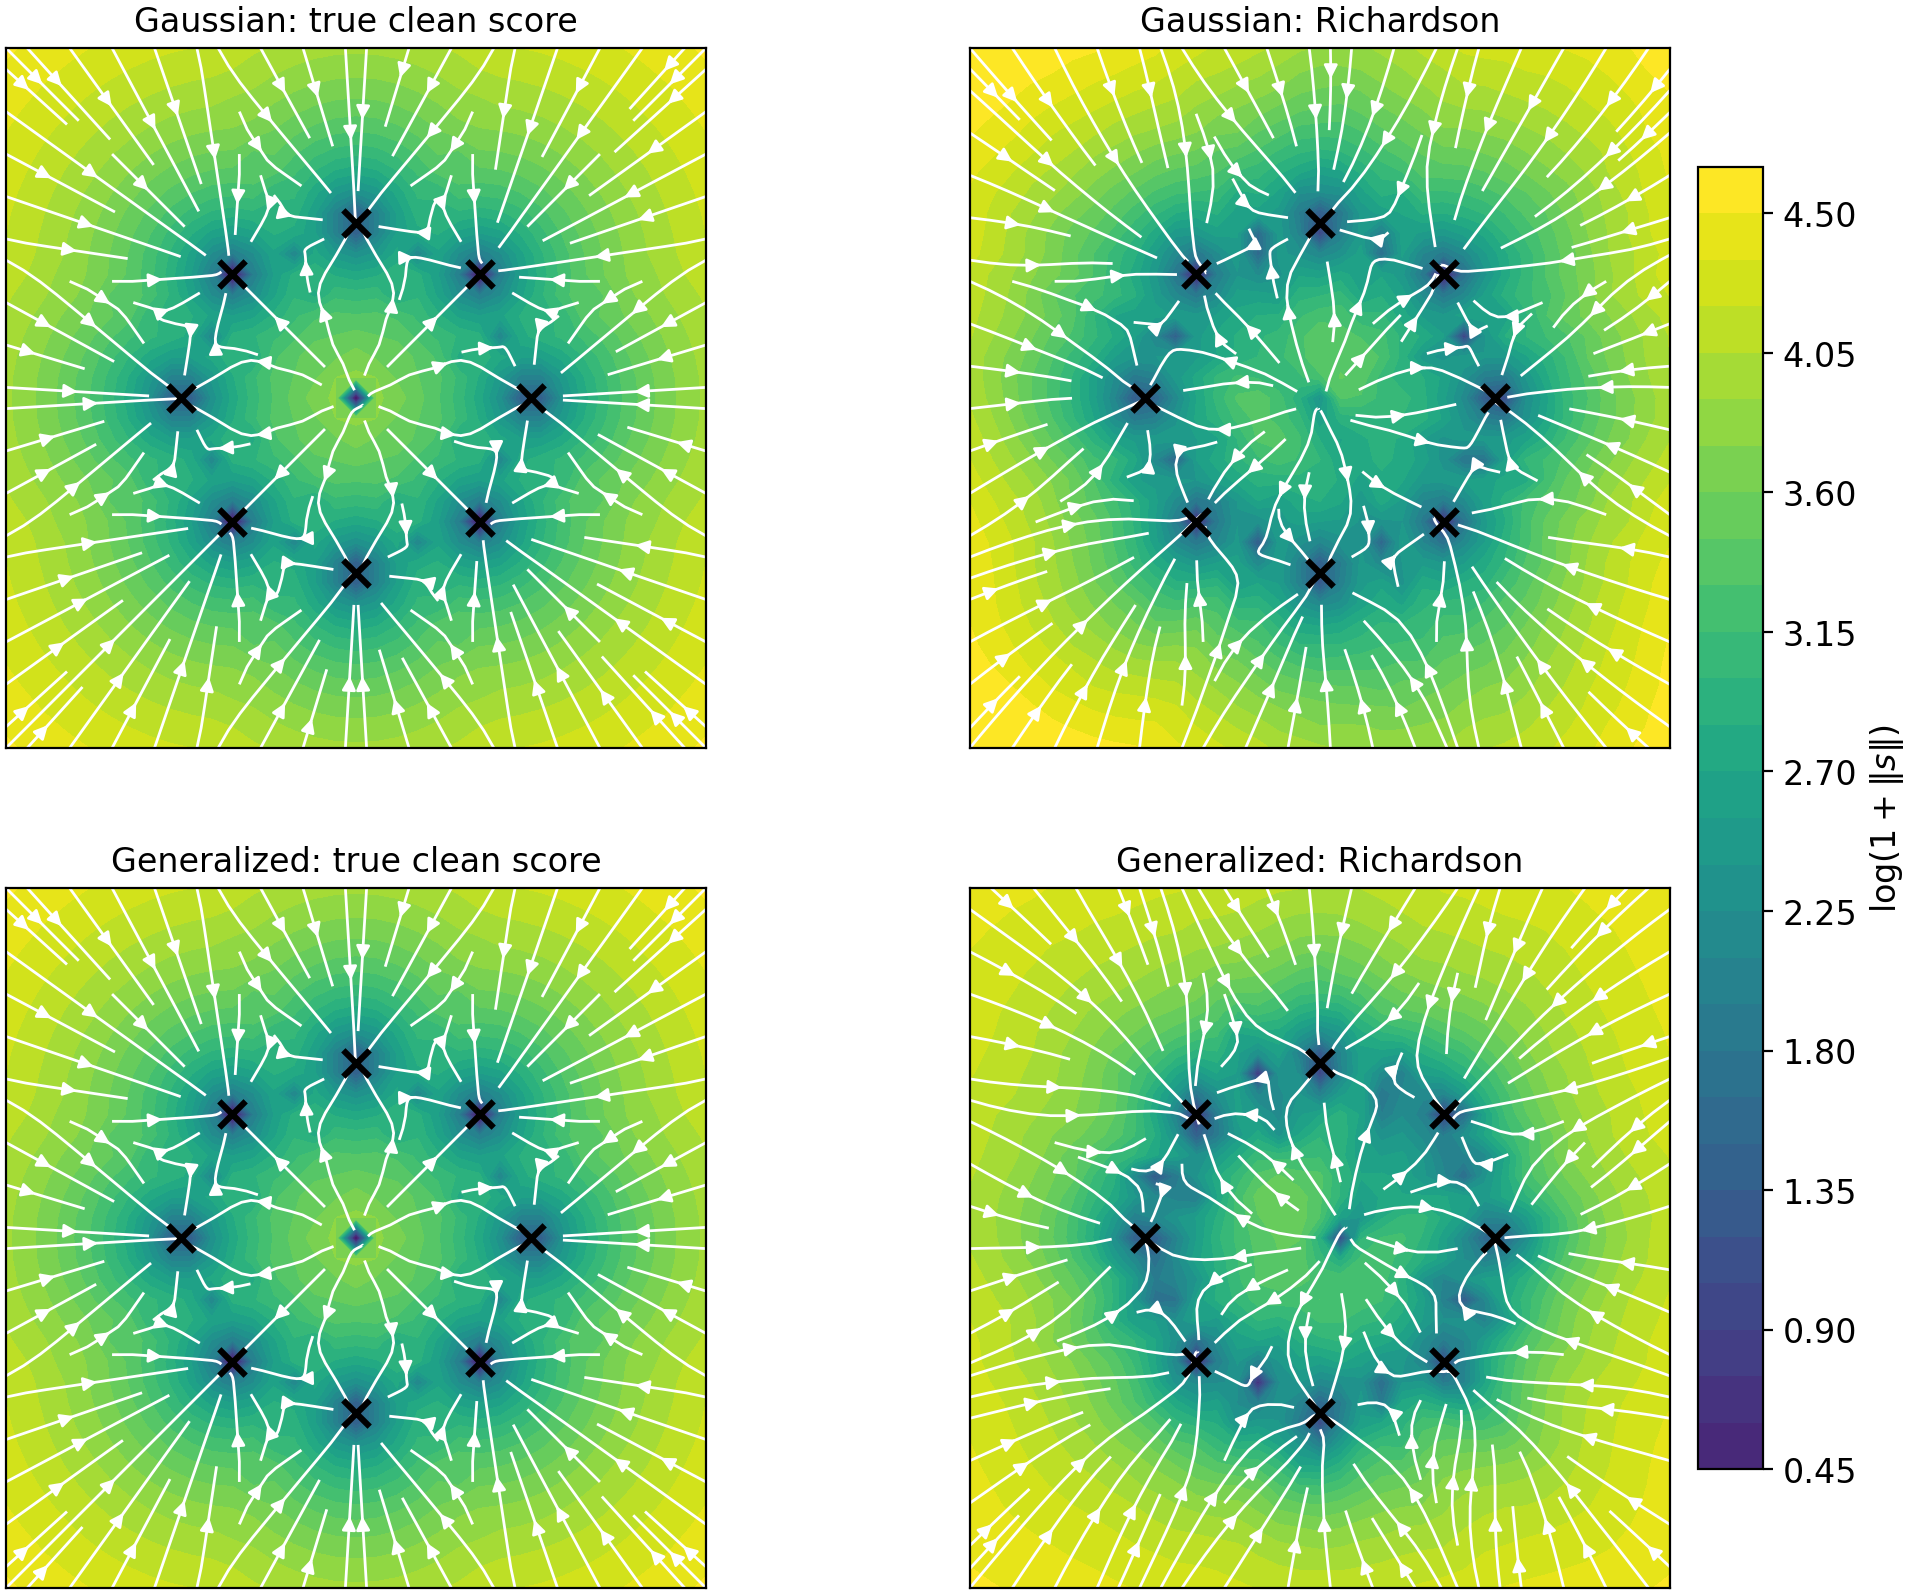

In [58]:
PRESENTATION_RC = {
    "figure.dpi": 200,
    "savefig.dpi": 300,
    "font.size": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "lines.linewidth": 1.2,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "figure.constrained_layout.use": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
}
mpl.rcParams.update(PRESENTATION_RC)

main_vmax = max(
    score_field_percentile(nice_fields, "s_clean_true"),
    score_field_percentile(nice_fields, "s_clean_hat"),
)

fig, axes = plt.subplots(
    len(nice_fields),
    2,
    figsize=(12, 10),
    dpi=mpl.rcParams["figure.dpi"],
    squeeze=True,
)

last_main = None
for row, (label, item) in enumerate(nice_fields.items()):
    sigma_text = rf"$\sigma_1={item['sigma1']:.3g},\; \sigma_2={item['sigma2']:.3g}$"

    last_main = draw_score_field(
        axes[row, 0],
        item["grid"],
        item["s_clean_true"],
        radius=item["radius"],
        title=f"{label}: true clean score",
        vmax=main_vmax,
        cmap="viridis",
    )
    last_main = draw_score_field(
        axes[row, 1],
        item["grid"],
        item["s_clean_hat"],
        radius=item["radius"],
        title=f"{label}: Richardson",
        vmax=main_vmax,
        cmap="viridis",
        fontsize=12,
    )

fig.colorbar(last_main, ax=axes, fraction=0.035, pad=0.015, label=r"$\log(1+\|s\|)$")
fig.savefig(NICE_SCORE_FIG, dpi=mpl.rcParams["savefig.dpi"], bbox_inches="tight")
print(f"Saved nice score-field figure to {NICE_SCORE_FIG}")
fig.savefig(NICE_SCORE_FIG.with_suffix(".pdf"), bbox_inches="tight")


Saved nice score-field residual figure to res/8gauss/score/nice_score_fields_richardson_error.png


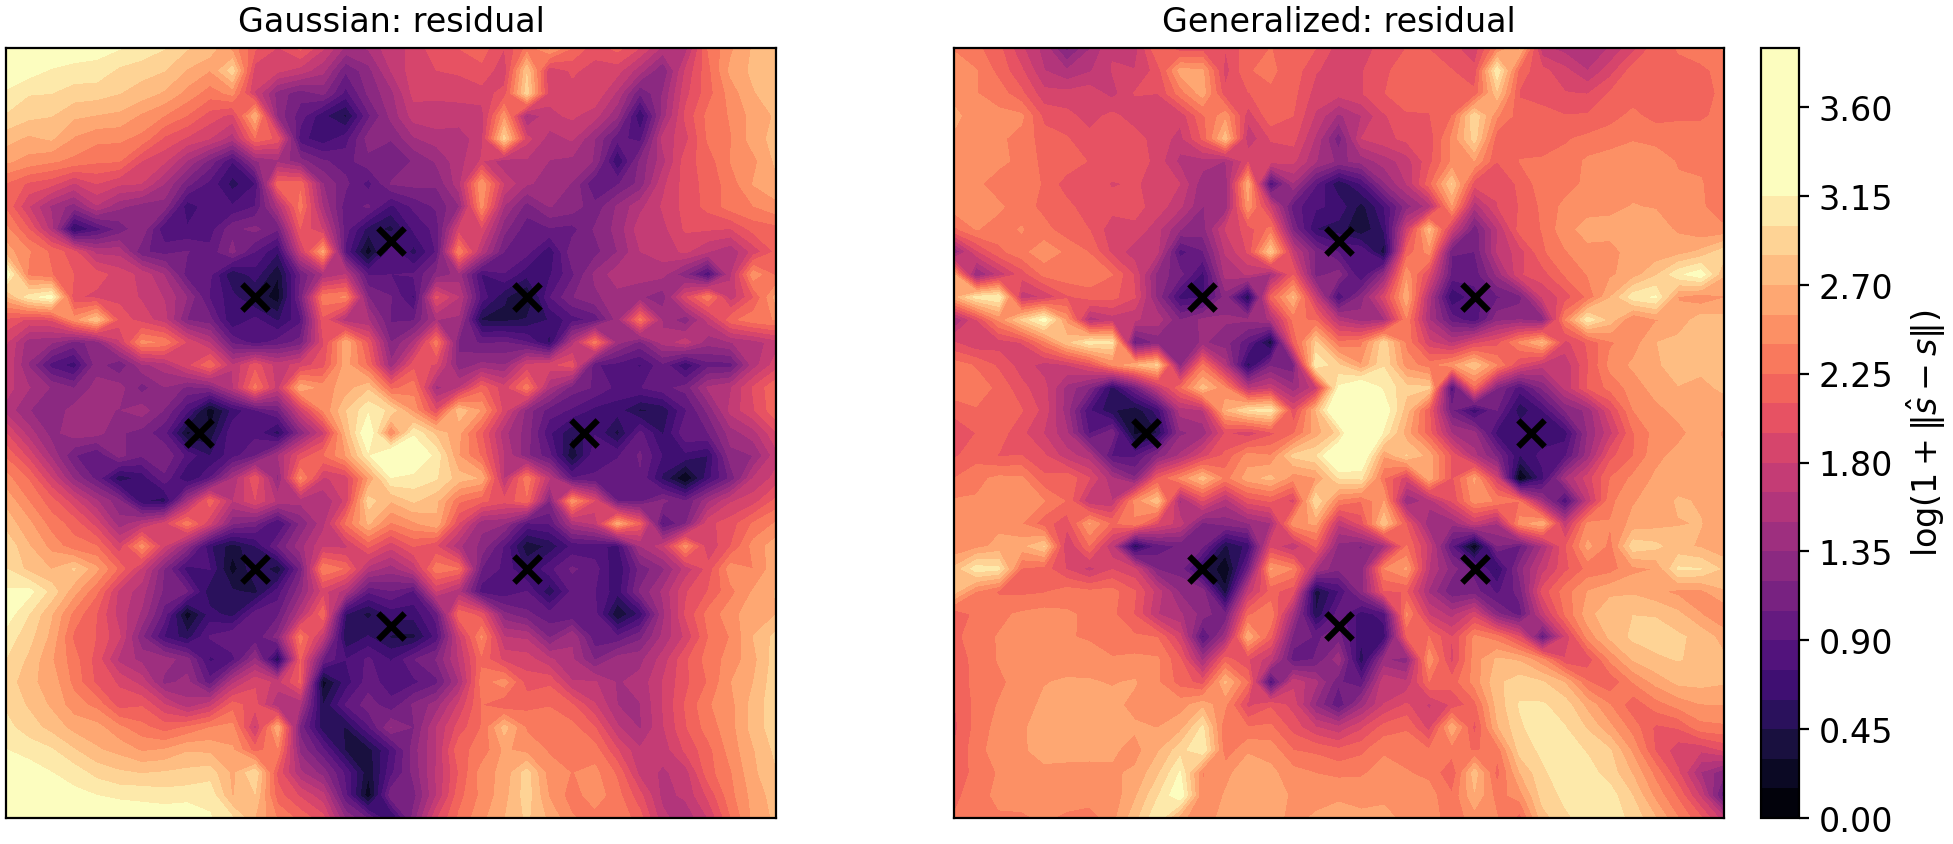

In [59]:
error_vmax = score_field_percentile(nice_fields, "s_clean_error")

fig, axes = plt.subplots(
    1,
    len(nice_fields),
    figsize=(12, 5),
    dpi=mpl.rcParams["figure.dpi"],
    squeeze=False,
)
axes = axes[0]

last_error = None
for ax, (label, item) in zip(axes, nice_fields.items()):
    xs, ys, _, _, mag = score_field_arrays(
        item["grid"],
        item["s_clean_error"],
    )
    last_error = ax.contourf(
        xs,
        ys,
        np.log1p(mag),
        levels=NICE_SCORE_STYLE["levels"],
        cmap="magma",
        vmin=0.0,
        vmax=np.log1p(error_vmax),
    )

    centers = eight_gaussians_centers(float(item["radius"])).cpu().numpy()
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="x",
        s=NICE_SCORE_STYLE["center_size"],
        c="black",
        linewidths=NICE_SCORE_STYLE["center_linewidth"],
        zorder=5,
    )

    lim = max(abs(xs).max(), abs(ys).max())
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{label}: residual", fontsize=12)

cbar = fig.colorbar(last_error, ax=axes, fraction=0.046, pad=0.02)
cbar.set_label(r"$\log(1+\|\hat s-s\|)$", fontsize=12)
cbar.ax.tick_params(labelsize=12)
fig.savefig(NICE_SCORE_FIG_ERROR, dpi=mpl.rcParams["savefig.dpi"], bbox_inches="tight")
print(f"Saved nice score-field residual figure to {NICE_SCORE_FIG_ERROR}")
fig.savefig(NICE_SCORE_FIG_ERROR.with_suffix(".pdf"), bbox_inches="tight")
